# Phân cụm hành vi khách hàng bằng mô hình RFM
## So sánh K-Means · Mini-Batch K-Means · K-Medoids (Scikit-learn vs. From Scratch bằng NumPy)

**Bài toán:** từ dữ liệu giao dịch thô (UCI *Online Retail*), xây dựng đặc trưng **R**ecency – **F**requency – **M**onetary cho từng khách hàng, sau đó phân cụm bằng 3 thuật toán và so sánh khả năng **chống nhiễu (outlier)**.

| Phần | Nội dung |
|---|---|
| **1** | Tải dữ liệu, làm sạch (trừ đơn hủy, bỏ mã phi hàng hóa), tổng hợp RFM, chuẩn hóa (bản chính + bản `log1p` đối chứng) |
| **2** | Cách 1 – Scikit-learn (`KMeans`, `MiniBatchKMeans`, `sklearn_extra.KMedoids`) + thí nghiệm bỏ outlier để đo khả năng chống nhiễu |
| **3** | Cách 2 – Cài đặt từ đầu chỉ bằng NumPy (`CustomKMeans`, `CustomMiniBatchKMeans`, `CustomKMedoids`) |
| **4** | So sánh & đánh giá bản From Scratch với Scikit-learn, chân dung cụm, kết luận |

In [1]:
import time
import warnings
from itertools import permutations
from typing import Dict, List, Literal, Optional, Tuple, Callable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# K-Medoids nằm trong gói phụ scikit-learn-extra:  pip install scikit-learn-extra
# Lưu ý: gói này đã ngừng bảo trì, có thể không build được với một số phiên bản Python/NumPy mới.
import sklearn_extra
from sklearn_extra.cluster import KMedoids

# Chỉ tắt cảnh báo phát sinh từ sklearn_extra (gói cũ); giữ nguyên cảnh báo của các thư viện khác.
warnings.filterwarnings("ignore", module="sklearn_extra")
# k-medoids++ của sklearn_extra gọi một hàm sklearn đã deprecated → cảnh báo phát ra từ module sklearn
warnings.filterwarnings("ignore", message=".*stable_cumsum.*", category=FutureWarning)

# ---- Cấu hình toàn cục (reproducible) ----
SEED: int = 42
N_CLUSTERS: int = 4
DATA_PATH: str = "data.csv"          # đổi đường dẫn nếu file nằm chỗ khác
FEATURES: List[str] = ["Recency", "Frequency", "Monetary"]

np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} "
      f"| scikit-learn-extra {sklearn_extra.__version__}")
print("Cấu hình xong | SEED =", SEED, "| K =", N_CLUSTERS)

numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | scikit-learn-extra 0.3.0
Cấu hình xong | SEED = 42 | K = 4


# PHẦN 1: TẢI DỮ LIỆU VÀ TIỀN XỬ LÝ
## 1.1. Đọc dữ liệu giao dịch thô
File CSV gốc của *Online Retail* dùng bảng mã `latin1` (có ký tự `£`), nên phải khai báo `encoding` nếu không `pandas` sẽ báo `UnicodeDecodeError`.

In [2]:
raw = pd.read_csv(DATA_PATH, encoding="latin1")
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], format="%m/%d/%Y %H:%M")

print(f"Kích thước dữ liệu thô: {raw.shape[0]:,} dòng × {raw.shape[1]} cột")
print(f"Khoảng thời gian: {raw['InvoiceDate'].min()}  →  {raw['InvoiceDate'].max()}")
display(raw.head())
raw.info()

Kích thước dữ liệu thô: 541,909 dòng × 8 cột
Khoảng thời gian: 2010-12-01 08:26:00  →  2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 33.1 MB


## 1.2. Làm sạch dữ liệu (Data Engineering)
Các quy tắc áp dụng tuần tự (in rõ số dòng bị loại ở mỗi bước):

1. Bỏ dòng **thiếu `CustomerID`** (không gán được cho khách hàng nào).
2. Bỏ **`UnitPrice ≤ 0`** (giá bằng 0/âm – dòng điều chỉnh, quà tặng, lỗi nhập liệu).
3. Bỏ các **`StockCode` không phải hàng hóa**: phí vận chuyển (`POST`, `DOT`, `C2`), điều chỉnh thủ công (`M`, `S`, `B`), chiết khấu (`D`), phí ngân hàng/sàn (`BANK CHARGES`, `AMAZONFEE`), quyên góp (`CRUK`) và `PADS` (giá 0,001). Các dòng này không phản ánh hành vi mua hàng.
4. **Hóa đơn hủy (`InvoiceNo` bắt đầu bằng `C`) không bị xóa** mà được tách riêng. Chúng có `Quantity < 0`, nên khi cộng vào doanh thu sẽ **trừ đúng** phần đã mua rồi hủy. Nếu chỉ xóa dòng hủy mà giữ đơn mua gốc, một đơn bị hủy toàn bộ vẫn được tính là doanh thu và sinh ra "khách cá voi" giả (kiểm chứng ở mục 1.3).

In [3]:
NON_PRODUCT_CODES = {"POST", "DOT", "C2", "M", "S", "B", "D",
                     "BANK CHARGES", "AMAZONFEE", "CRUK", "PADS"}

df = raw.copy()
cleaning_rules = [
    ("Thiếu CustomerID",          lambda d: d["CustomerID"].notna()),
    ("UnitPrice <= 0",            lambda d: d["UnitPrice"] > 0),
    ("StockCode không phải hàng", lambda d: ~d["StockCode"].astype(str).isin(NON_PRODUCT_CODES)),
]
for name, rule in cleaning_rules:
    before = len(df)
    df = df[rule(df)]
    print(f"{name:<28s} → loại {before - len(df):>8,} dòng | còn lại {len(df):>8,}")

df["CustomerID"] = df["CustomerID"].astype(int)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]
df["IsCancel"] = df["InvoiceNo"].astype(str).str.startswith("C")
df = df.reset_index(drop=True)

purchases = df[~df["IsCancel"]]
cancels = df[df["IsCancel"]]
# Sau khi tách: đơn mua luôn có Quantity > 0, đơn hủy luôn có Quantity < 0
assert (purchases["Quantity"] > 0).all() and (cancels["Quantity"] < 0).all()

print(f"\nĐơn mua : {len(purchases):>8,} dòng | doanh thu gộp £{purchases['TotalPrice'].sum():>13,.0f}")
print(f"Đơn hủy : {len(cancels):>8,} dòng | bị hủy       £{-cancels['TotalPrice'].sum():>13,.0f}")

Thiếu CustomerID             → loại  135,080 dòng | còn lại  406,829
UnitPrice <= 0               → loại       40 dòng | còn lại  406,789


StockCode không phải hàng    → loại    1,913 dòng | còn lại  404,876

Đơn mua :  396,337 dòng | doanh thu gộp £    8,761,067
Đơn hủy :    8,539 dòng | bị hủy       £      474,403


## 1.3. Tổng hợp mô hình RFM theo từng `CustomerID`

| Chỉ số | Cách tính |
|---|---|
| **Recency** | Số ngày từ lần **mua** gần nhất (không tính dòng hủy) đến *snapshot date* (= ngày mua cuối cùng + 1) – càng nhỏ càng “nóng” |
| **Frequency** | Số hóa đơn **mua** phân biệt (`nunique` của `InvoiceNo`) |
| **Monetary** | **Doanh thu ròng** = tổng `Quantity × UnitPrice` của đơn mua **cộng** đơn hủy (đơn hủy mang dấu âm) |

Khách có Monetary ròng ≤ 0 (mua rồi hủy gần hết/toàn bộ, hoặc hủy hàng đã mua trước 12/2010 nằm ngoài phạm vi dữ liệu) bị loại vì không có hành vi mua thực.

In [4]:
snapshot_date = purchases["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm_audit = (
    purchases.groupby("CustomerID")
             .agg(LastPurchase=("InvoiceDate", "max"),
                  Frequency=("InvoiceNo", "nunique"),
                  GrossMonetary=("TotalPrice", "sum"))
)
# ròng = mua + hủy; làm tròn tới xu để sai số số thực (~1e-14) không bị coi là doanh thu dương
rfm_audit["Monetary"] = df.groupby("CustomerID")["TotalPrice"].sum().round(2)
rfm_audit["Recency"] = (snapshot_date - rfm_audit["LastPurchase"]).dt.days

only_cancel = df["CustomerID"].nunique() - len(rfm_audit)
non_positive = (rfm_audit["Monetary"] <= 0).sum()
rfm = rfm_audit.loc[rfm_audit["Monetary"] > 0, FEATURES].copy()

print("Snapshot date:", snapshot_date.date())
print(f"Khách chỉ có đơn hủy (không có đơn mua): {only_cancel}")
print(f"Khách có Monetary ròng <= 0 → loại   : {non_positive}")
print("Số khách hàng dùng để phân cụm       :", len(rfm))
display(rfm.head())
display(rfm.describe().T.round(2))

Snapshot date: 2011-12-10
Khách chỉ có đơn hủy (không có đơn mua): 28
Khách có Monetary ròng <= 0 → loại   : 14
Số khách hàng dùng để phân cụm       : 4320


,Recency,Frequency,Monetary
CustomerID,,,
12347,2,7,4310.00
12348,75,4,1437.24
12349,19,1,1457.55
12350,310,1,294.40
12352,36,7,1265.41


,count,mean,std,min,25%,50%,75%,max
Recency,4320.0,92.55,100.12,1.0,18.0,51.00,143.00,374.00
Frequency,4320.0,4.26,7.65,1.0,1.0,2.00,5.00,206.00
Monetary,4320.0,1919.17,8303.91,2.9,300.5,653.99,1611.43,278778.02


### Kiểm chứng: vì sao phải trừ đơn hủy
Bảng dưới xếp khách theo doanh thu **gộp** (chỉ cộng đơn mua, tức cách tính khi xóa dòng hủy) và đặt cạnh doanh thu **ròng**. Hai khách thuộc nhóm lớn nhất theo doanh thu gộp thực chất đã hủy gần như toàn bộ đơn hàng.

In [5]:
audit = rfm_audit.assign(CancelledShare=1 - rfm_audit["Monetary"] / rfm_audit["GrossMonetary"])
cols = ["Recency", "Frequency", "GrossMonetary", "Monetary", "CancelledShare"]
top_gross = audit.sort_values("GrossMonetary", ascending=False).head(8)[cols]
display(top_gross.style.format({"GrossMonetary": "£{:,.0f}", "Monetary": "£{:,.2f}",
                                "CancelledShare": "{:.1%}"}))

for cid in (12346, 16446):
    r = audit.loc[cid]
    print(f"Khách {cid}: gộp £{r.GrossMonetary:,.2f} → ròng £{r.Monetary:,.2f} "
          f"(hủy {r.CancelledShare:.1%}) → {'LOẠI' if r.Monetary <= 0 else 'giữ, nhưng hết là cá voi'}")

,Recency,Frequency,GrossMonetary,Monetary,CancelledShare
CustomerID,,,,,
14646,2,72,"£279,138","£278,778.02",0.1%
18102,1,60,"£259,657","£259,657.30",0.0%
17450,8,46,"£194,551","£189,735.53",2.5%
16446,1,2,"£168,472",£2.90,100.0%
14911,1,198,"£136,276","£128,882.13",5.4%
12415,24,20,"£124,565","£123,638.18",0.7%
14156,10,54,"£116,730","£113,855.32",2.5%
17511,3,31,"£91,062","£88,138.20",3.2%


Khách 12346: gộp £77,183.60 → ròng £0.00 (hủy 100.0%) → LOẠI
Khách 16446: gộp £168,472.50 → ròng £2.90 (hủy 100.0%) → giữ, nhưng hết là cá voi


## 1.4. Quan sát Outlier (được giữ lại có chủ đích)
Sau khi đã trừ đơn hủy, các giá trị cực lớn còn lại là **khách mua sỉ thật**: một số ít khách chi tiêu gấp hàng chục đến hàng trăm lần khách bình thường. Phân phối của F và M vẫn lệch phải rất mạnh.

Top 5 khách hàng có Monetary lớn nhất:


,Recency,Frequency,Monetary
CustomerID,,,
14646,2,72,278778.0
18102,1,60,259657.3
17450,8,46,189735.5
14911,1,198,128882.1
12415,24,20,123638.2


Monetary: max / median = 426 lần
Số khách có |z-score| > 3 theo Monetary: 32 (0.74%) → vẫn GIỮ LẠI


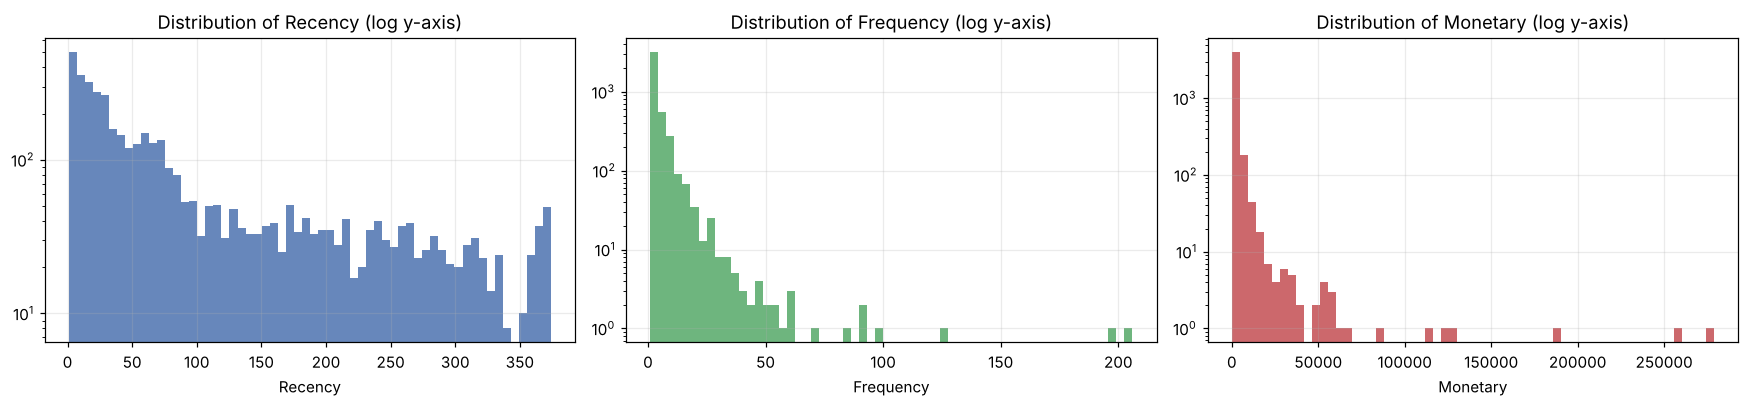

In [6]:
print("Top 5 khách hàng có Monetary lớn nhất:")
display(rfm.sort_values("Monetary", ascending=False).head(5).round(1))

m = rfm["Monetary"]
z = (m - m.mean()) / m.std()
print(f"Monetary: max / median = {m.max() / m.median():.0f} lần")
print(f"Số khách có |z-score| > 3 theo Monetary: {(z.abs() > 3).sum()} "
      f"({(z.abs() > 3).mean():.2%}) → vẫn GIỮ LẠI")

fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col, color in zip(axs, FEATURES, ["#4c72b0", "#55a868", "#c44e52"]):
    ax.hist(rfm[col], bins=60, color=color, alpha=0.85)
    ax.set_yscale("log")
    ax.set_title(f"Distribution of {col} (log y-axis)")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

## 1.5. Chuẩn hóa: bản chính `X` và bản đối chứng `X_log`
R (ngày), F (số đơn) và M (£) có thang đo chênh nhau hàng nghìn lần. K-Means dựa trên khoảng cách Euclid, nên nếu không chuẩn hóa thì M sẽ “nuốt” hai chiều còn lại:

$$z = \frac{x - \mu}{\sigma}$$

**StandardScaler không trung tính với dữ liệu lệch.** Chuẩn hóa là phép co giãn tuyến tính, nên outlier vẫn là outlier. Nhưng $\sigma$ của F và M bị **chính các outlier thổi phồng**, nên phần lõi (đa số khách hàng) bị nén vào một dải rất hẹp quanh 0. Khi đó khoảng cách giữa các khách bình thường trở nên rất nhỏ so với khoảng cách tới outlier, và điều này ảnh hưởng đến **mọi** thuật toán dùng khoảng cách.

Để tách hiệu ứng của **thuật toán** khỏi hiệu ứng của **cách chuẩn hóa**, notebook dùng hai ma trận:
* `X` – StandardScaler trên R, F, M gốc. Giữ nguyên outlier; đây là bối cảnh chính để so sánh khả năng chống nhiễu.
* `X_log` – `log1p` cho F và M rồi mới StandardScaler. Đây là bản đối chứng, cũng là cách làm phổ biến trong thực tế RFM.

In [7]:
scaler = StandardScaler()
X: np.ndarray = scaler.fit_transform(rfm[FEATURES].to_numpy(dtype=float))

rfm_log = rfm[FEATURES].astype(float).copy()
rfm_log[["Frequency", "Monetary"]] = np.log1p(rfm_log[["Frequency", "Monetary"]])
scaler_log = StandardScaler()
X_log: np.ndarray = scaler_log.fit_transform(rfm_log.to_numpy())

def iqr(v: np.ndarray) -> float:
    q1, q3 = np.quantile(v, [0.25, 0.75])
    return float(q3 - q1)

print("X.shape         :", X.shape)
print("Mean / Std sau scale:", X.mean(axis=0).round(6), X.std(axis=0).round(6))
print("Max  sau scale (X)    :", X.max(axis=0).round(1), " ← outlier vẫn còn nguyên")
print("Max  sau scale (X_log):", X_log.max(axis=0).round(1))
print()
print("Độ rộng 50% khách ở giữa (IQR) sau chuẩn hóa – càng nhỏ thì lõi càng bị nén:")
display(pd.DataFrame({"X (StandardScaler)": [iqr(X[:, j]) for j in range(3)],
                      "X_log (log1p + StandardScaler)": [iqr(X_log[:, j]) for j in range(3)]},
                     index=FEATURES).round(3))

X.shape         : (4320, 3)
Mean / Std sau scale: [ 0. -0. -0.] [1. 1. 1.]
Max  sau scale (X)    : [ 2.8 26.4 33.3]  ← outlier vẫn còn nguyên
Max  sau scale (X_log): [2.8 5.8 4.8]

Độ rộng 50% khách ở giữa (IQR) sau chuẩn hóa – càng nhỏ thì lõi càng bị nén:


,X (StandardScaler),X_log (log1p + StandardScaler)
Recency,1.249,1.249
Frequency,0.523,1.611
Monetary,0.158,1.343


## 1.6. Hàm tiện ích dùng chung (NumPy thuần)
Các hàm dưới đây chỉ phục vụ **đánh giá & vẽ hình**, không chứa logic phân cụm, nên dùng chung cho cả hai cách tiếp cận.

* `compute_inertia` – WCSS: $\sum_i \lVert x_i-\mu_{c_i}\rVert^2$
* `compute_abs_cost` – tổng khoảng cách tuyệt đối (hàm mục tiêu của K-Medoids): $\sum_i \lVert x_i-m_{c_i}\rVert_2$
* `relabel_by_monetary` – đánh lại số hiệu cụm theo Monetary của tâm, đồng thời trả về hoán vị để sắp xếp các thông tin đi kèm (ví dụ chỉ số medoid).
* `profile_clusters` – chân dung cụm bằng **trung vị**, kèm trung bình Monetary để thấy outlier kéo trung bình đi bao xa.
* `fit_timed` – đo thời gian `fit` bằng **trung vị của nhiều lần chạy** thay vì một lần.
* `match_centers` – ghép **một-một** tâm của hai mô hình sao cho tổng khoảng cách nhỏ nhất (vét cạn $K!$ hoán vị, vì $K$ nhỏ).

> Không dùng “khoảng cách giữa tâm và trung vị cụm” để đo khả năng chống nhiễu. Medoid được chọn để tối thiểu tổng khoảng cách tuyệt đối, nên theo định nghĩa đã nằm gần trung vị; phép đo đó tự nghiêng về K-Medoids. Khả năng chống nhiễu được đo bằng thí nghiệm bỏ outlier ở mục 2.5.

In [8]:
def compute_inertia(X: np.ndarray, labels: np.ndarray, centers: np.ndarray) -> float:
    """WCSS = tổng bình phương khoảng cách Euclid từ mỗi điểm tới tâm cụm của nó."""
    diff = X - centers[labels]
    return float(np.einsum("ij,ij->", diff, diff))


def compute_abs_cost(X: np.ndarray, labels: np.ndarray, centers: np.ndarray) -> float:
    """Tổng khoảng cách Euclid (không bình phương) từ điểm tới tâm cụm."""
    return float(np.linalg.norm(X - centers[labels], axis=1).sum())


def relabel_by_monetary(labels: np.ndarray, centers: np.ndarray, col: int = 2
                        ) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Đánh lại số hiệu cụm theo thứ tự tăng dần của tâm trên trục Monetary.

    Trả về (nhãn mới, tâm đã sắp xếp, order) với order[k_mới] = k_cũ, dùng để sắp xếp
    các thông tin đi kèm theo cụm (vd. medoid_indices_[order]).
    """
    order = np.argsort(centers[:, col])
    inverse = np.empty_like(order)
    inverse[order] = np.arange(len(order))
    return inverse[labels], centers[order], order


def profile_clusters(rfm_df: pd.DataFrame, labels: np.ndarray) -> pd.DataFrame:
    """Chân dung từng cụm (đơn vị gốc): kích thước, TRUNG VỊ R/F/M và trung bình M để đối chiếu."""
    tmp = rfm_df[FEATURES].copy()
    tmp["Cluster"] = labels
    g = tmp.groupby("Cluster")
    out = pd.DataFrame({
        "Size": g.size(),
        "Recency (median)": g["Recency"].median(),
        "Frequency (median)": g["Frequency"].median(),
        "Monetary (median)": g["Monetary"].median(),
        "Monetary (mean)": g["Monetary"].mean(),
    })
    return out.round(1)


def fit_timed(make_model: Callable[[], object], X: np.ndarray, repeats: int = 3
              ) -> Tuple[object, np.ndarray, float]:
    """Fit `repeats` lần (cùng random_state nên cùng kết quả); trả về model, nhãn, trung vị thời gian."""
    times = []
    for _ in range(repeats):
        model = make_model()
        t0 = time.perf_counter()
        labels = model.fit_predict(X)
        times.append(time.perf_counter() - t0)
    return model, labels, float(np.median(times))


def match_centers(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    """Ghép 1-1 tâm A[i] ↔ B[p(i)] với tổng khoảng cách nhỏ nhất; trả về khoảng cách từng cặp."""
    D = np.sqrt(((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=-1))
    rows = np.arange(len(A))
    best = min(permutations(range(len(B))), key=lambda p: D[rows, list(p)].sum())
    return D[rows, list(best)]


def summarize_results(results: Dict[str, dict], X: np.ndarray,
                      silhouette_fn: Callable[[np.ndarray, np.ndarray], float]) -> pd.DataFrame:
    """Bảng tổng hợp chỉ số cho một dict kết quả {tên: {labels, centers, time}}."""
    rows = []
    for name, res in results.items():
        labels, centers = res["labels"], res["centers"]
        rows.append({
            "Model": name,
            "Inertia (WCSS)": compute_inertia(X, labels, centers),
            "Abs. cost (ΣL2)": compute_abs_cost(X, labels, centers),
            "Silhouette": silhouette_fn(X, labels),
            "Time (s, median)": res["time"],
            "Cluster sizes": sorted(np.bincount(labels, minlength=centers.shape[0]).tolist(), reverse=True),
        })
    return pd.DataFrame(rows).set_index("Model")


def plot_clusters_1x3(X: np.ndarray, results: Dict[str, dict], suptitle: str,
                      axes_idx: Tuple[int, int] = (1, 2), zoom: bool = False) -> None:
    """Vẽ subplot 1x3: mỗi model một ô; tâm/medoid là dấu X đỏ đậm.

    axes_idx : cặp đặc trưng đem vẽ (0=R, 1=F, 2=M). F–M là nơi có outlier; R–M là nơi
               phần lớn các cụm thực sự tách nhau (nên cần xem cả hai).
    zoom     : True => thu hẹp khung nhìn vào 99% dữ liệu để thấy cấu trúc vùng dày đặc.
    """
    i, j = axes_idx
    fig, axs = plt.subplots(1, 3, figsize=(19, 5.6), sharex=True, sharey=True)
    palette = plt.get_cmap("tab10")

    for ax, (name, res) in zip(axs, results.items()):
        labels, centers, _ = relabel_by_monetary(res["labels"], res["centers"])
        for k in range(centers.shape[0]):
            mask = labels == k
            ax.scatter(X[mask, i], X[mask, j], s=11, alpha=0.55, color=palette(k),
                       label=f"Cluster {k} (n={mask.sum()})")
        ax.scatter(centers[:, i], centers[:, j], marker="X", s=330, c="red",
                   edgecolors="black", linewidths=1.6, zorder=10,
                   label=res.get("center_name", "Center"))
        ax.set_title(f"{name}\n{res.get('subtitle', '')}", fontsize=11)
        ax.set_xlabel(f"{FEATURES[i]} (standardized)")
        ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
    axs[0].set_ylabel(f"{FEATURES[j]} (standardized)")

    if zoom:
        for idx, setter in ((i, axs[0].set_xlim), (j, axs[0].set_ylim)):
            lo, hi = X[:, idx].min(), np.quantile(X[:, idx], 0.99)
            pad = 0.15 * (hi - lo)
            setter(lo - pad, hi + pad)

    view = f"{FEATURES[i]}–{FEATURES[j]}"
    fig.suptitle(f"{suptitle}  [{view}, " + ("zoomed to the central 99% of data]" if zoom else "full data, including outliers]"),
                 fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

print("Đã định nghĩa các hàm tiện ích.")

Đã định nghĩa các hàm tiện ích.


# PHẦN 2: CÁCH 1 – THỰC CHIẾN VỚI SCIKIT-LEARN & SKLEARN-EXTRA
## 2.1. Chọn số cụm K (Elbow + Silhouette)
Chạy K-Means với K = 2…8 trên **cả hai** không gian `X` và `X_log` để xem outlier ảnh hưởng đến việc chọn K như thế nào.

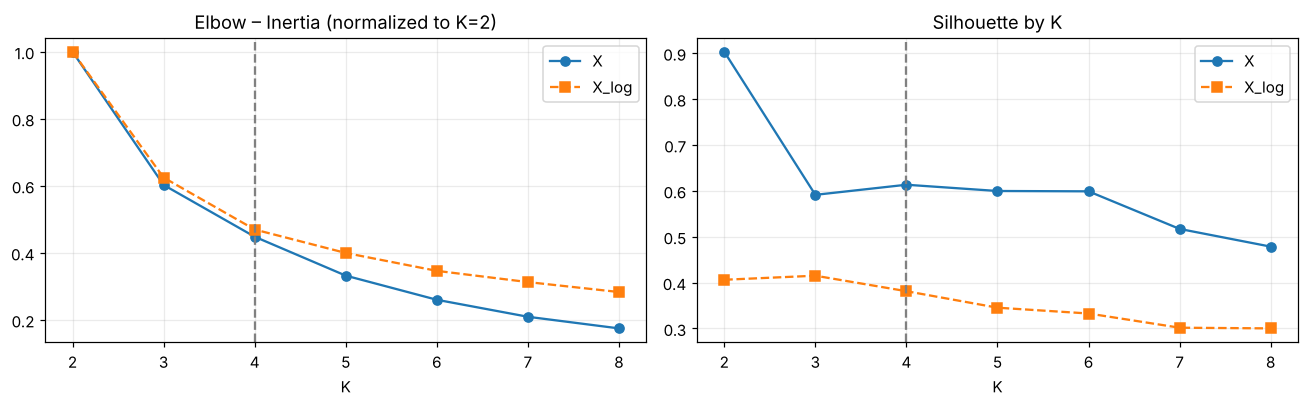

X                                             X_log             \
    Inertia Silhouette Smallest cluster (customers)   Inertia Silhouette   
K                                                                          
2  8985.628      0.903                           22  6834.675      0.406   
3  5415.516      0.591                           22  4269.423      0.415   
4  4027.589      0.613                            6  3210.350      0.381   
5  2984.745      0.600                            3  2732.384      0.345   
6  2337.532      0.599                            2  2367.715      0.333   
7  1882.151      0.517                            3  2138.868      0.302   
8  1570.497      0.478                            2  1935.944      0.300   

                                
  Smallest cluster (customers)  
K                               
2                         1826  
3                          982  
4                          545  
5                          290  
6                          278  
7                          200  
8                          168

In [9]:
k_range = list(range(2, 9))
k_scan = {}
for space, M in (("X", X), ("X_log", X_log)):
    inertias, sils, smallest = [], [], []
    for k in k_range:
        km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(M)
        inertias.append(km_k.inertia_)
        sils.append(silhouette_score(M, km_k.labels_))
        smallest.append(int(np.bincount(km_k.labels_).min()))
    k_scan[space] = pd.DataFrame({"Inertia": inertias, "Silhouette": sils,
                                  "Smallest cluster (customers)": smallest}, index=pd.Index(k_range, name="K"))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for space, style in (("X", "o-"), ("X_log", "s--")):
    t = k_scan[space]
    axs[0].plot(k_range, t["Inertia"] / t["Inertia"].iloc[0], style, label=space)
    axs[1].plot(k_range, t["Silhouette"], style, label=space)
axs[0].set_title("Elbow – Inertia (normalized to K=2)")
axs[1].set_title("Silhouette by K")
for ax in axs:
    ax.axvline(N_CLUSTERS, ls="--", c="gray"); ax.set_xlabel("K"); ax.legend()
plt.tight_layout(); plt.show()
display(pd.concat(k_scan, axis=1).round(3))

**Đọc kết quả**
* Trên `X`, Silhouette cao nhất ở **K = 2 (0,903)**, nhưng cụm nhỏ hơn chỉ có 22 khách. Đó là phép tách “cá voi” khỏi phần còn lại, không phải một phân khúc. Silhouette bị outlier chi phối nên không đáng tin trong không gian này. Từ K = 4 trở đi, cụm nhỏ nhất chỉ còn 2–6 khách.
* Trên `X_log`, Silhouette thấp hơn hẳn (0,30–0,42), cao nhất ở K = 3; K = 4 đạt 0,381. Đường Elbow không có điểm gãy rõ. Dữ liệu RFM này **không có cụm tách bạch tự nhiên**.
* Vì vậy **K = 4 là quyết định nghiệp vụ** (ánh xạ sang 4 nhóm hành động: giá trị cao / đang hoạt động / có nguy cơ / đã rời bỏ), không phải kết luận rút ra từ Elbow hay Silhouette. K được cố định cho cả ba thuật toán để so sánh công bằng.

## 2.2. Huấn luyện 3 mô hình bằng `fit_predict` (trên `X`)
* `KMeans` – Lloyd + khởi tạo **k-means++**, `n_init=10`.
* `MiniBatchKMeans` – cập nhật tâm trên từng mini-batch (`batch_size=1024`), cấu hình mặc định của sklearn: `n_init=10` chỉ dùng để **chọn khởi tạo** trên một tập con, sau đó chạy tối ưu **một** lần và dừng sớm khi inertia không cải thiện trong 10 bước.
* `KMedoids` (`sklearn_extra`) – thuật toán **PAM**, khoảng cách `euclidean`, khởi tạo `k-medoids++`, chạy một lần.

Thời gian là **trung vị của 3 lần chạy**.

In [10]:
sk_factories: Dict[str, Callable[[], object]] = {
    "K-Means": lambda: KMeans(n_clusters=N_CLUSTERS, init="k-means++", n_init=10, random_state=SEED),
    "Mini-Batch K-Means": lambda: MiniBatchKMeans(n_clusters=N_CLUSTERS, batch_size=1024, n_init=10,
                                                  random_state=SEED),
    "K-Medoids (PAM)": lambda: KMedoids(n_clusters=N_CLUSTERS, metric="euclidean", method="pam",
                                        init="k-medoids++", random_state=SEED),
}

sk_results: Dict[str, dict] = {}
for name, make in sk_factories.items():
    model, labels, elapsed = fit_timed(make, X, repeats=3)
    sk_results[name] = {
        "labels": labels,
        "centers": model.cluster_centers_,
        "time": elapsed,
        "center_name": "Medoid" if "Medoids" in name else "Centroid",
        "model": model,
    }

sk_summary = summarize_results(sk_results, X, silhouette_fn=silhouette_score)
for name, res in sk_results.items():
    res["subtitle"] = (f"Inertia={sk_summary.loc[name, 'Inertia (WCSS)']:,.0f} | "
                       f"Silhouette={sk_summary.loc[name, 'Silhouette']:.3f}")
display(sk_summary.round(3))

,Inertia (WCSS),Abs. cost (ΣL2),Silhouette,"Time (s, median)",Cluster sizes
Model,,,,,
K-Means,4027.589,2647.660,0.613,0.028,"[3137, 1074, 103, 6]"
Mini-Batch K-Means,6349.677,2318.872,0.373,0.017,"[1889, 1339, 942, 150]"
K-Medoids (PAM),7496.183,2122.466,0.459,13.287,"[2262, 785, 658, 615]"


## 2.3. Trực quan hóa
Mỗi dấu **X đỏ** là tâm cụm. Vẽ ba góc nhìn:
* **F–M toàn cảnh:** outlier nằm ở đây; thấy tâm nào bị “hút” ra phía outlier.
* **F–M zoom 99%:** thấy phần lõi dày đặc; medoid luôn nằm trên một điểm dữ liệu thật.
* **R–M zoom 99%:** phần lớn các cụm khác nhau chủ yếu ở **Recency**, nên chỉ nhìn F–M sẽ thấy các cụm chồng lên nhau và dễ hiểu sai.

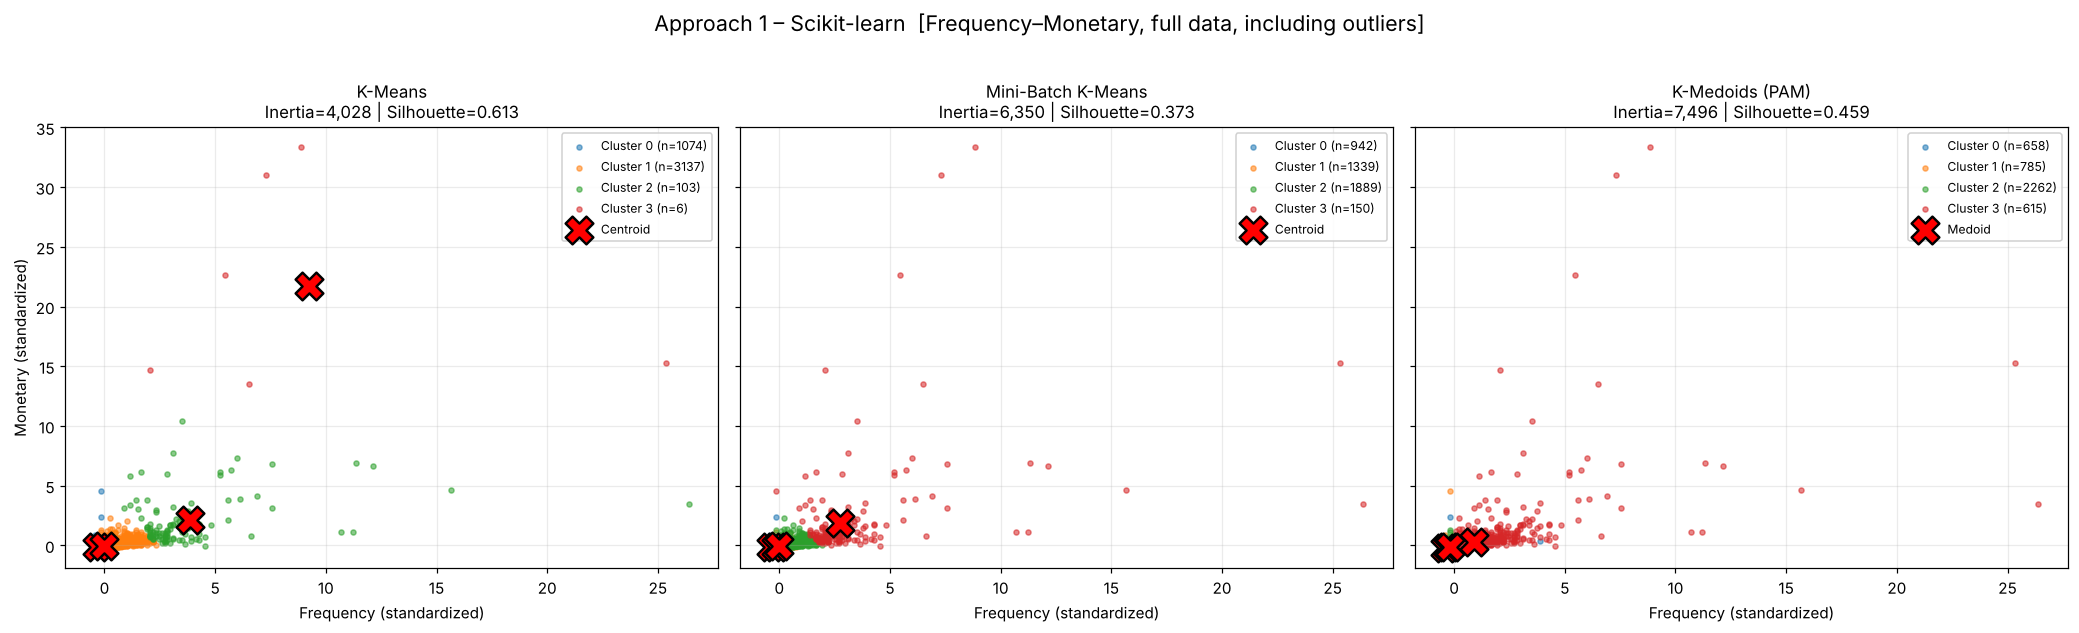

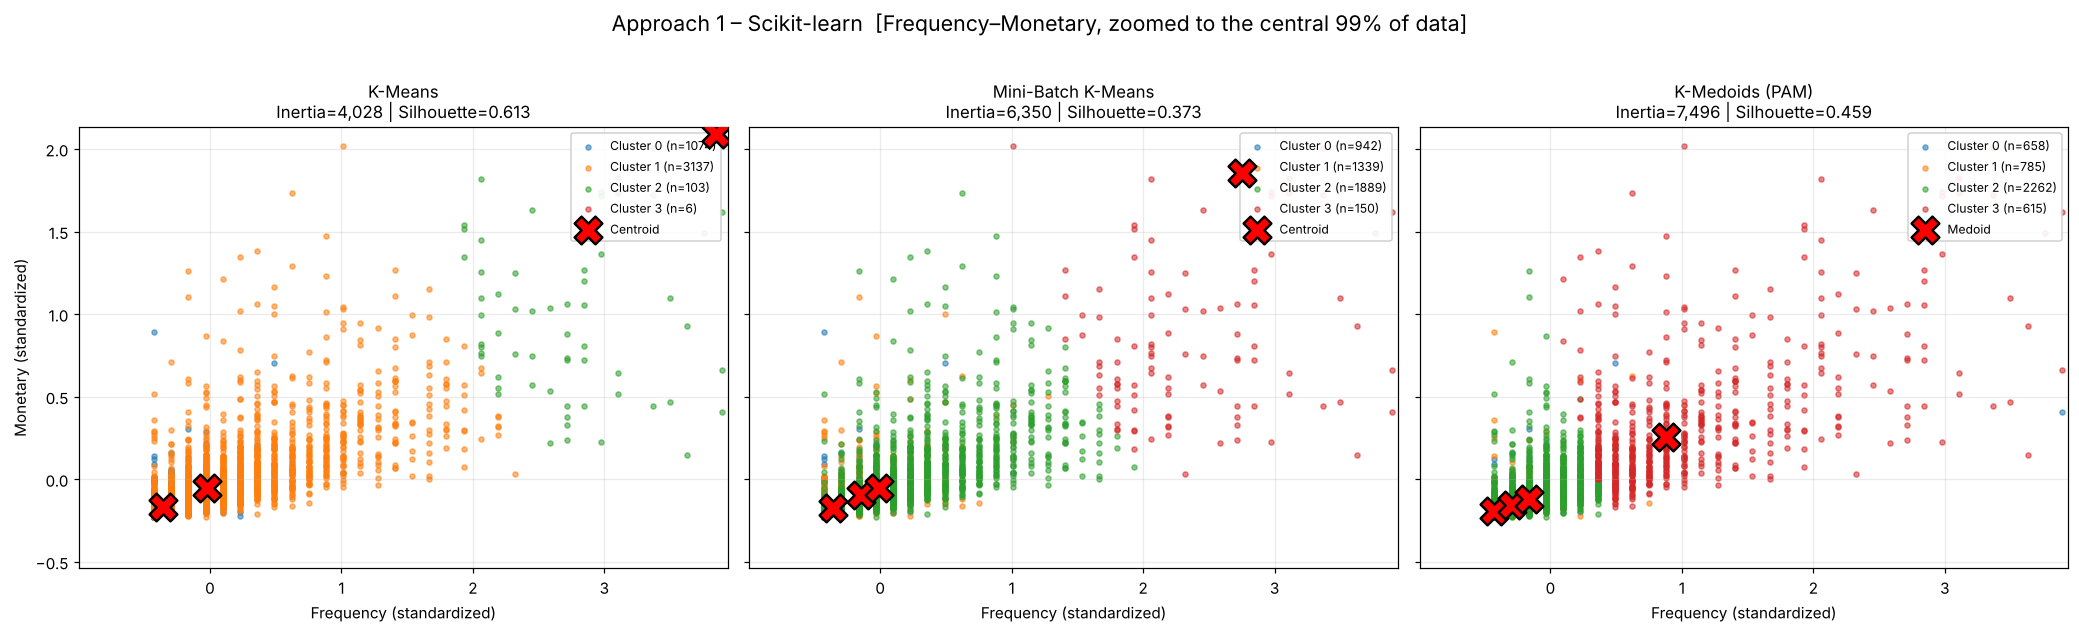

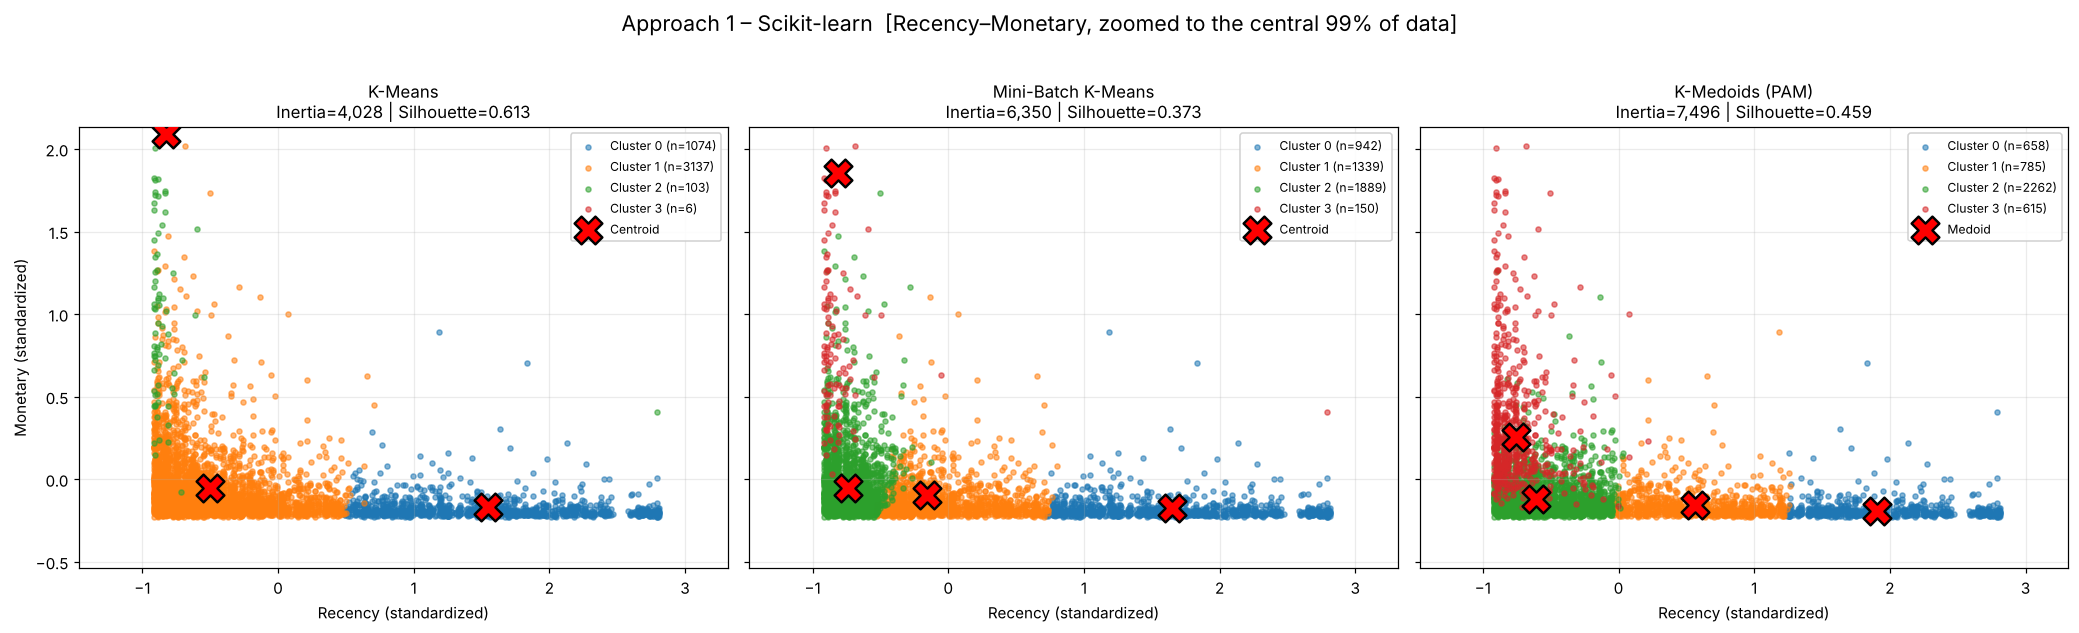

In [11]:
title_sk = "Approach 1 – Scikit-learn"
plot_clusters_1x3(X, sk_results, title_sk, axes_idx=(1, 2), zoom=False)
plot_clusters_1x3(X, sk_results, title_sk, axes_idx=(1, 2), zoom=True)
plot_clusters_1x3(X, sk_results, title_sk, axes_idx=(0, 2), zoom=True)

## 2.4. Soi vào tâm cụm theo đơn vị gốc (R: ngày, F: số đơn, M: £)
K-Medoids có lợi thế diễn giải: mỗi medoid là **một khách hàng có thật** (tra được `CustomerID`). Cụm được đánh số lại theo Monetary của tâm, và danh sách medoid cũng được sắp **cùng thứ tự** với bảng.

> Với Mini-Batch K-Means, tâm là trung bình di động của các mini-batch nên **không trùng hẳn** với trung bình thực của cụm sau lần gán cuối. Đây là đặc điểm của thuật toán, không phải lỗi.

In [12]:
for name, res in sk_results.items():
    labels, centers, order = relabel_by_monetary(res["labels"], res["centers"])
    center_rfm = pd.DataFrame(scaler.inverse_transform(centers), columns=FEATURES).round(1)
    center_rfm.index.name = "Cluster"
    if "Medoids" in name:
        center_rfm.insert(0, "Medoid CustomerID", rfm.index[res["model"].medoid_indices_[order]])
    print(f"\n=== {name}: tâm cụm (đơn vị gốc) ===")
    display(center_rfm)
    print(f"--- Chân dung cụm ({name}) ---")
    display(profile_clusters(rfm, labels))


=== K-Means: tâm cụm (đơn vị gốc) ===


,Recency,Frequency,Monetary
Cluster,,,
0,247.4,1.5,517.6
1,42.4,4.1,1484.3
2,10.1,33.7,19262.3
3,7.7,75.0,182424.4


--- Chân dung cụm (K-Means) ---


,Size,Recency (median),Frequency (median),Monetary (median),Monetary (mean)
Cluster,,,,,
0,1074,243.0,1.0,303.3,517.6
1,3137,31.0,3.0,860.4,1484.3
2,103,4.0,26.0,12334.1,19262.3
3,6,5.0,57.0,159308.8,182424.4



=== Mini-Batch K-Means: tâm cụm (đơn vị gốc) ===


,Recency,Frequency,Monetary
Cluster,,,
0,257.8,1.5,488.8
1,76.5,3.1,1145.2
2,18.3,4.2,1460.2
3,10.9,25.3,17334.8


... (2 outputs left out)


=== K-Medoids (PAM): tâm cụm (đơn vị gốc) ===


,Medoid CustomerID,Recency,Frequency,Monetary
Cluster,,,,
0,12834,283.0,1.0,312.4
1,15402,149.0,2.0,626.4
2,17886,32.0,3.0,899.6
3,16670,17.0,11.0,4022.5


--- Chân dung cụm (K-Medoids (PAM)) ---


,Size,Recency (median),Frequency (median),Monetary (median),Monetary (mean)
Cluster,,,,,
0,658,283.0,1.0,266.2,433.8
1,785,149.0,2.0,459.9,750.1
2,2262,31.0,2.0,692.0,997.7
3,615,10.0,11.0,3965.2,8390.1


### Nhận xét nhanh
* **K-Means dành 2/4 cụm cho outlier:** một cụm 6 khách (trung vị M ≈ £159 nghìn) và một cụm 103 khách; hơn 4.200 khách còn lại chỉ được chia thành hai nhóm theo Recency. Đây là hệ quả của WCSS (bình phương khoảng cách) cộng với việc StandardScaler nén lõi (IQR của M sau chuẩn hóa chỉ 0,16, xem 1.5).
* **K-Medoids** chia phần lõi thành bốn nhóm có ý nghĩa hơn. Nhưng nó **không loại bỏ** outlier: toàn bộ khách cá voi bị gộp vào cụm 3 (615 khách), nên trung bình M của cụm 3 (£8.390) gấp đôi trung vị (£3.965). Vì vậy chân dung cụm phải đọc theo trung vị.
* **Mini-Batch** (cấu hình mặc định của sklearn) có Silhouette thấp nhất (0,373). Cơ chế dời các tâm ít điểm (`reassignment_ratio`) khiến không hình thành cụm riêng cho cá voi, nên kết quả nằm giữa K-Means và K-Medoids (xem 4.4).
* Inertia của K-Means *thường* nhỏ hơn của K-Medoids vì K-Means tối ưu trực tiếp WCSS. Điều này chỉ chắc chắn khi so trên **cùng một phân hoạch**, vì cả hai chỉ đạt cực tiểu địa phương. Ngược lại, K-Medoids có Abs. cost nhỏ nhất vì đó là hàm mục tiêu của nó. Hàm mục tiêu của một thuật toán không dùng để phân xử giữa các họ thuật toán được.
* Nhóm “outlier” ở đây là **khách mua sỉ thật**. Một cụm VIP riêng (như cụm 6 khách của K-Means) có thể *hữu ích* về mặt kinh doanh, nên “bị outlier kéo” chưa hẳn là nhược điểm. Câu hỏi đúng là: thuật toán có chia **phần lõi** ổn định hay không. Mục 2.5 kiểm tra điều này.

## 2.5. Đo khả năng chống nhiễu: thí nghiệm bỏ outlier
Câu hỏi cần trả lời: **sự có mặt của outlier làm thay đổi cách phân cụm *phần lõi* đến mức nào?**

1. Đánh dấu outlier = khách có $|z| > 3$ ở ít nhất một chiều của `X`. Tập này dùng chung cho cả `X` và `X_log`.
2. Với mỗi thuật toán: fit trên **toàn bộ** dữ liệu và fit lại trên **chỉ phần lõi**, cùng tham số và cùng tọa độ (không fit lại scaler).
3. So sánh nhãn của các điểm lõi giữa hai lần fit bằng **ARI**. ARI ≈ 1 nghĩa là outlier gần như không ảnh hưởng đến cách chia lõi.
4. **ARI nền:** fit hai lần trên lõi với hai `random_state` khác nhau. Con số này cho biết bao nhiêu phần dao động là do bản thân thuật toán ngẫu nhiên (quan trọng với Mini-Batch), không phải do outlier.
5. Đếm số cụm bị outlier **chiếm đa số**, tức số cụm thuật toán phải “dành riêng” cho outlier.

In [13]:
is_out = (np.abs(X) > 3).any(axis=1)
core = ~is_out
print(f"Outlier (|z|>3 ở ít nhất một chiều của X): {is_out.sum()} khách ({is_out.mean():.2%})")

def make_sk(name: str, seed: int):
    if name == "K-Means":
        return KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=seed)
    if name == "Mini-Batch K-Means":
        return MiniBatchKMeans(n_clusters=N_CLUSTERS, batch_size=1024, n_init=10, random_state=seed)
    return KMedoids(n_clusters=N_CLUSTERS, metric="euclidean", method="pam",
                    init="k-medoids++", random_state=seed)

rob_rows, log_results = [], {}
for space, M in (("X", X), ("X_log", X_log)):
    for name in sk_factories:
        if space == "X":
            lab_full = sk_results[name]["labels"]                 # đã fit ở 2.2
        else:
            mdl = make_sk(name, SEED).fit(M)
            lab_full = mdl.labels_
            log_results[name] = {"labels": lab_full, "centers": mdl.cluster_centers_, "model": mdl}
        lab_core = make_sk(name, SEED).fit_predict(M[core])
        lab_core_alt = make_sk(name, SEED + 1).fit_predict(M[core])
        sizes = np.bincount(lab_full, minlength=N_CLUSTERS)
        out_share = np.bincount(lab_full, weights=is_out.astype(float), minlength=N_CLUSTERS) / np.maximum(sizes, 1)
        rob_rows.append({
            "Không gian": space, "Model": name,
            "ARI lõi: có vs không outlier": adjusted_rand_score(lab_full[core], lab_core),
            "ARI nền (2 seed, chỉ lõi)": adjusted_rand_score(lab_core, lab_core_alt),
            "Số cụm do outlier chiếm đa số": int((out_share > 0.5).sum()),
            "Cụm nhỏ nhất (KH)": int(sizes.min()),
        })

robust = pd.DataFrame(rob_rows).set_index(["Không gian", "Model"])
display(robust.round(3))

Outlier (|z|>3 ở ít nhất một chiều của X): 62 khách (1.44%)


ARI lõi: có vs không outlier  \
Không gian Model                                              
X          K-Means                                    0.532   
           Mini-Batch K-Means                         0.365   
           K-Medoids (PAM)                            0.952   
X_log      K-Means                                    0.698   
           Mini-Batch K-Means                         0.910   
           K-Medoids (PAM)                            0.940   

                               ARI nền (2 seed, chỉ lõi)  \
Không gian Model                                           
X          K-Means                                 0.984   
           Mini-Batch K-Means                      0.923   
           K-Medoids (PAM)                         0.780   
X_log      K-Means                                 0.996   
           Mini-Batch K-Means                      0.663   
           K-Medoids (PAM)                         1.000   

                               Số cụm do outlier chiếm đa số  \
Không gian Model                                               
X          K-Means                                         2   
           Mini-Batch K-Means                              0   
           K-Medoids (PAM)                                 0   
X_log      K-Means                                         0   
           Mini-Batch K-Means                              0   
           K-Medoids (PAM)                                 0   

                               Cụm nhỏ nhất (KH)  
Không gian Model                                  
X          K-Means                             6  
           Mini-Batch K-Means                150  
           K-Medoids (PAM)                   615  
X_log      K-Means                           545  
           Mini-Batch K-Means                477  
           K-Medoids (PAM)                   912

**Đọc kết quả**
* **Trên `X`:** bỏ 62 outlier (1,44%) làm K-Means chia lại phần lõi rất khác (ARI 0,53, trong khi ARI nền ≈ 0,98). Vậy dao động này **do outlier gây ra**, không phải do ngẫu nhiên. K-Medoids giữ cách chia lõi gần như nguyên vẹn (ARI 0,95). ARI nền của K-Medoids chỉ 0,78 (PAM với khởi tạo khác dừng ở cực tiểu khác), nghĩa là ảnh hưởng của outlier lên K-Medoids nằm trong mức dao động do khởi tạo. Mini-Batch bị ảnh hưởng nặng nhất (ARI 0,37).
* **Trên `X_log`:** không còn cụm nào do outlier chiếm đa số, và cụm nhỏ nhất có từ 477 khách trở lên. Tuy vậy K-Means vẫn đổi cách chia lõi đáng kể (ARI 0,70, nền 1,00): ở K = 4 dữ liệu không có ranh giới tự nhiên (Silhouette 0,38) nên ranh giới dễ xê dịch. K-Medoids vẫn ổn định nhất (0,94). Mini-Batch có ARI nền chỉ 0,66, tức tự nó đã dao động nhiều hơn mức outlier gây ra, nên **không kết luận được** về khả năng chống nhiễu của nó trong không gian này.
* **Kết luận:** khả năng chống nhiễu của K-Medoids được xác nhận bằng một phép đo không thiên vị. Việc `log1p` làm outlier không còn chiếm riêng cụm cho thấy một phần lớn mức “nhạy outlier” của K-Means đến từ **cách chuẩn hóa**, không chỉ từ thuật toán.

# PHẦN 3: CÁCH 2 – CODE FROM SCRATCH (CHỈ DÙNG NUMPY)
Phần này **hoàn toàn độc lập** với Phần 2: không import `KMeans`, `MiniBatchKMeans`, `KMedoids` hay bất kỳ hàm clustering nào; thuật toán chỉ dùng `numpy`.

## 3.0. Nền tảng vectorized: ma trận khoảng cách
Tránh vòng lặp lồng nhau bằng đẳng thức khai triển bình phương khoảng cách Euclid:

$$\lVert a-b\rVert^2 = \lVert a\rVert^2 + \lVert b\rVert^2 - 2\,a^\top b$$

Với $A\in\mathbb{R}^{n\times d}$, $B\in\mathbb{R}^{k\times d}$, toàn bộ ma trận $n\times k$ được tính bằng **một phép nhân ma trận** `A @ B.T`. Chỉ có Manhattan phải lặp theo $d=3$ đặc trưng (không lặp theo số điểm).

In [14]:
def pairwise_sq_euclidean(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    """Ma trận bình phương khoảng cách Euclid (n×k) bằng phép nhân ma trận."""
    a2 = np.einsum("ij,ij->i", A, A)[:, None]
    b2 = np.einsum("ij,ij->i", B, B)[None, :]
    d2 = a2 + b2 - 2.0 * (A @ B.T)
    np.maximum(d2, 0.0, out=d2)            # chặn sai số làm tròn âm nhỏ
    return d2


def pairwise_manhattan(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    """Ma trận khoảng cách Manhattan (L1); vòng lặp chỉ chạy theo số chiều d (rất nhỏ)."""
    d1 = np.zeros((A.shape[0], B.shape[0]))
    for j in range(A.shape[1]):
        d1 += np.abs(A[:, j][:, None] - B[:, j][None, :])
    return d1


def pairwise_distance(A: np.ndarray, B: np.ndarray,
                      metric: Literal["euclidean", "manhattan"] = "euclidean") -> np.ndarray:
    """Ma trận khoảng cách (không bình phương) giữa mọi cặp (A_i, B_j)."""
    if metric == "euclidean":
        return np.sqrt(pairwise_sq_euclidean(A, B))
    if metric == "manhattan":
        return pairwise_manhattan(A, B)
    raise ValueError(f"metric không hỗ trợ: {metric!r}")


def one_hot(labels: np.ndarray, n_clusters: int) -> np.ndarray:
    """Ma trận one-hot (n×K); dùng để cộng điểm theo cụm bằng một phép nhân ma trận."""
    oh = np.zeros((labels.shape[0], n_clusters))
    oh[np.arange(labels.shape[0]), labels] = 1.0
    return oh


def _check_X(X: np.ndarray, n_clusters: int) -> np.ndarray:
    X = np.asarray(X, dtype=float)
    if X.ndim != 2:
        raise ValueError("X phải là mảng 2 chiều (n_samples, n_features).")
    if X.shape[0] < n_clusters:
        raise ValueError("Số mẫu phải >= n_clusters.")
    return X

print("OK")

OK


## 3.1. `CustomKMeans` (thuật toán Lloyd)

**Hàm mục tiêu:** $J=\sum_{i=1}^{N}\lVert x_i-\mu_{c_i}\rVert^2$

| Bước | Công thức |
|---|---|
| Khởi tạo | Chọn ngẫu nhiên K điểm dữ liệu (Forgy). Tùy chọn `k-means++` |
| Gán | $c_i=\arg\min_k\lVert x_i-\mu_k\rVert^2$ |
| Cập nhật | $\mu_k=\frac{1}{\lvert C_k\rvert}\sum_{x\in C_k}x$ (đạt cực tiểu của $J_k$ vì $\partial^2 J_k/\partial\mu^2=2\lvert C_k\rvert I\succ0$) |

Mỗi bước đều không làm tăng $J$ ⇒ hội tụ về cực tiểu **địa phương**; vì vậy chạy `n_init` lần và giữ lần có $J$ nhỏ nhất. Cụm rỗng được xử lý bằng cách đặt tâm vào điểm xa tâm hiện tại nhất.

In [15]:
class CustomKMeans:
    """K-Means (Lloyd) cài đặt bằng NumPy.

    Nguyên lý: luân phiên (1) gán mỗi điểm vào tâm gần nhất theo Euclid^2 và
    (2) cập nhật tâm = trung bình cụm. Mỗi bước giảm (không tăng) WCSS
    J = sum_i ||x_i - mu_{c_i}||^2 nên thuật toán hội tụ về cực tiểu địa phương.

    Parameters
    ----------
    n_clusters   : số cụm K.
    init         : 'random' (chọn K điểm ngẫu nhiên) hoặc 'k-means++'.
    n_init       : số lần chạy với khởi tạo khác nhau; giữ nghiệm có inertia nhỏ nhất.
    max_iter     : số vòng lặp tối đa mỗi lần chạy.
    tol          : ngưỡng dịch chuyển tâm (nhân với phương sai trung bình của dữ liệu).
    random_state : seed để tái lập kết quả.
    """

    def __init__(self, n_clusters: int = 4, init: Literal["random", "k-means++"] = "random",
                 n_init: int = 10, max_iter: int = 300, tol: float = 1e-4,
                 random_state: Optional[int] = None) -> None:
        self.n_clusters = n_clusters
        self.init = init
        self.n_init = n_init
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.cluster_centers_: Optional[np.ndarray] = None
        self.labels_: Optional[np.ndarray] = None
        self.inertia_: float = np.inf
        self.n_iter_: int = 0
        self.inertia_history_: List[float] = []

    # ---- 1. Khởi tạo -------------------------------------------------
    def _init_centroids(self, X: np.ndarray, rng: np.random.Generator) -> np.ndarray:
        """Khởi tạo K tâm: ngẫu nhiên (Forgy) hoặc k-means++ (xác suất ∝ D(x)^2)."""
        n = X.shape[0]
        if self.init == "random":
            return X[rng.choice(n, size=self.n_clusters, replace=False)].copy()

        centers = np.empty((self.n_clusters, X.shape[1]))
        centers[0] = X[rng.integers(n)]
        closest_d2 = pairwise_sq_euclidean(X, centers[:1]).ravel()
        for c in range(1, self.n_clusters):          # lặp theo K, không theo n
            total = closest_d2.sum()
            probs = closest_d2 / total if total > 0 else None
            centers[c] = X[rng.choice(n, p=probs)]
            closest_d2 = np.minimum(closest_d2, pairwise_sq_euclidean(X, centers[c:c + 1]).ravel())
        return centers

    # ---- 2. Gán cụm --------------------------------------------------
    @staticmethod
    def _assign_clusters(X: np.ndarray, centroids: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        """Trả về (nhãn, bình phương khoảng cách tới tâm gần nhất) cho mọi điểm."""
        d2 = pairwise_sq_euclidean(X, centroids)             # (n, K) một phép nhân ma trận
        labels = np.argmin(d2, axis=1)
        return labels, d2[np.arange(X.shape[0]), labels]

    # ---- 3. Cập nhật tâm ---------------------------------------------
    def _update_centroids(self, X: np.ndarray, labels: np.ndarray, min_d2: np.ndarray) -> np.ndarray:
        """Tâm mới = trung bình các điểm thuộc cụm; tổng theo cụm tính bằng one-hot^T @ X."""
        onehot = one_hot(labels, self.n_clusters)
        counts = onehot.sum(axis=0)
        centroids = (onehot.T @ X) / np.maximum(counts, 1.0)[:, None]

        empty = np.flatnonzero(counts == 0)                  # xử lý cụm rỗng
        if empty.size:
            d2 = min_d2.copy()
            for k in empty:
                far = int(np.argmax(d2))
                centroids[k] = X[far]
                d2[far] = 0.0
        return centroids

    # ---- Một lần chạy ------------------------------------------------
    def _single_run(self, X: np.ndarray, rng: np.random.Generator
                    ) -> Tuple[np.ndarray, np.ndarray, float, int, List[float]]:
        centers = self._init_centroids(X, rng)
        tol_abs = self.tol * float(np.mean(np.var(X, axis=0)))
        history: List[float] = []
        prev_labels: Optional[np.ndarray] = None
        n_iter = 0
        for n_iter in range(1, self.max_iter + 1):
            labels, min_d2 = self._assign_clusters(X, centers)
            new_centers = self._update_centroids(X, labels, min_d2)
            shift = float(np.sum((new_centers - centers) ** 2))
            centers = new_centers
            history.append(float(min_d2.sum()))
            if prev_labels is not None and np.array_equal(labels, prev_labels):
                break                                         # phép gán không đổi => hội tụ
            prev_labels = labels
            if shift <= tol_abs:
                break                                         # tâm gần như đứng yên
        labels, min_d2 = self._assign_clusters(X, centers)
        return centers, labels, float(min_d2.sum()), n_iter, history

    # ---- API ---------------------------------------------------------
    def fit(self, X: np.ndarray) -> "CustomKMeans":
        X = _check_X(X, self.n_clusters)
        rng = np.random.default_rng(self.random_state)
        for _ in range(self.n_init):
            centers, labels, inertia, n_iter, hist = self._single_run(X, rng)
            if inertia < self.inertia_:
                self.cluster_centers_, self.labels_ = centers, labels
                self.inertia_, self.n_iter_, self.inertia_history_ = inertia, n_iter, hist
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        return self._assign_clusters(np.asarray(X, dtype=float), self.cluster_centers_)[0]

    def fit_predict(self, X: np.ndarray) -> np.ndarray:
        return self.fit(X).labels_

print("CustomKMeans OK")

CustomKMeans OK


## 3.2. `CustomMiniBatchKMeans` (Sculley, 2010)

Thay vì dùng toàn bộ N điểm mỗi vòng, mỗi bước chỉ rút ngẫu nhiên một **mini-batch** $B$ ($|B|=$ `batch_size`):

1. Gán các điểm trong $B$ vào tâm gần nhất.
2. Cập nhật tâm bằng **trung bình di động** (learning rate giảm dần theo số điểm đã thấy của từng tâm). Với $n_k$ = số điểm tích lũy của tâm $k$ và $b_k$, $S_k$ = số điểm và tổng điểm của $B$ rơi vào cụm $k$:

$$\mu_k \leftarrow \frac{n_k\,\mu_k + S_k}{n_k + b_k}\;=\;(1-\eta_k)\,\mu_k+\eta_k\,\bar{x}_{B,k},\qquad \eta_k=\frac{b_k}{n_k+b_k},\quad n_k\leftarrow n_k+b_k$$

Đây chính là **trung bình cộng dồn** của mọi điểm từng được gán cho tâm $k$, nên quá trình học ổn định dần (η → 0). Mỗi bước tốn $O(|B|\,K\,d)$ thay vì $O(N\,K\,d)$: đánh đổi một chút chất lượng để lấy tốc độ.

**Điều kiện dừng** (giống sklearn):
* *Inertia không cải thiện:* theo dõi trung bình trượt mũ (EWA) của inertia trên từng batch, với $\alpha = \min(1, 2|B|/(N+1))$. Nếu EWA không giảm trong `max_no_improvement` bước liên tiếp thì dừng.
* *Tâm đứng yên* (tùy chọn, `tol > 0`): tổng bình phương dịch chuyển tâm ≤ `tol` × phương sai trung bình của dữ liệu.
* Tối đa `max_iter` bước.

Dừng theo dịch chuyển tâm một mình là không đủ: khi một batch có hoặc không có vài outlier, tâm của cụm nhỏ nhảy đi một đoạn lớn, nên điều kiện “tâm đứng yên” hầu như không bao giờ thỏa.

In [16]:
class CustomMiniBatchKMeans:
    """Mini-Batch K-Means cài đặt bằng NumPy.

    Nguyên lý: mỗi vòng rút ngẫu nhiên một mini-batch, gán nhãn cho batch, rồi cập nhật
    tâm bằng trung bình di động có trọng số đếm (per-center count):
        mu_k <- (n_k * mu_k + S_k) / (n_k + b_k),   n_k <- n_k + b_k
    với b_k, S_k là số điểm và tổng điểm của batch trong cụm k. Learning rate
    eta_k = b_k / (n_k + b_k) giảm dần => tâm hội tụ về trung bình cụm.

    Parameters
    ----------
    n_clusters         : số cụm K.
    batch_size         : kích thước mini-batch.
    init               : 'random' hoặc 'k-means++'.
    n_init             : số lần chạy đầy đủ; chọn nghiệm có inertia (trên TOÀN BỘ dữ liệu) nhỏ nhất.
    max_iter           : số bước mini-batch tối đa mỗi lần chạy.
    max_no_improvement : dừng sớm nếu EWA của inertia theo batch không giảm trong ngần ấy bước.
    tol                : ngưỡng dịch chuyển tâm (nhân phương sai TB dữ liệu); 0 = tắt tiêu chí này.
    random_state       : seed để tái lập.
    """

    def __init__(self, n_clusters: int = 4, batch_size: int = 1024,
                 init: Literal["random", "k-means++"] = "random", n_init: int = 5,
                 max_iter: int = 300, max_no_improvement: int = 10, tol: float = 0.0,
                 random_state: Optional[int] = None) -> None:
        self.n_clusters = n_clusters
        self.batch_size = batch_size
        self.init = init
        self.n_init = n_init
        self.max_iter = max_iter
        self.max_no_improvement = max_no_improvement
        self.tol = tol
        self.random_state = random_state
        self.cluster_centers_: Optional[np.ndarray] = None
        self.labels_: Optional[np.ndarray] = None
        self.inertia_: float = np.inf
        self.n_steps_: int = 0
        self.counts_: Optional[np.ndarray] = None

    def _init_centroids(self, X: np.ndarray, rng: np.random.Generator) -> np.ndarray:
        # Tái sử dụng logic khởi tạo của CustomKMeans (cùng cách chọn tâm ban đầu).
        return CustomKMeans(n_clusters=self.n_clusters, init=self.init)._init_centroids(X, rng)

    @staticmethod
    def _assign_clusters(X: np.ndarray, centroids: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        d2 = pairwise_sq_euclidean(X, centroids)
        labels = np.argmin(d2, axis=1)
        return labels, d2[np.arange(X.shape[0]), labels]

    def _update_centroids(self, Xb: np.ndarray, labels_b: np.ndarray,
                          centers: np.ndarray, counts: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        """Cập nhật tâm theo trung bình di động (vectorized trên toàn batch)."""
        onehot = one_hot(labels_b, self.n_clusters)
        batch_counts = onehot.sum(axis=0)                    # b_k
        batch_sums = onehot.T @ Xb                           # S_k
        new_counts = counts + batch_counts                   # n_k + b_k

        new_centers = centers.copy()
        active = batch_counts > 0                            # chỉ cập nhật tâm có điểm trong batch
        new_centers[active] = (centers[active] * counts[active, None] + batch_sums[active]) \
                              / new_counts[active, None]
        return new_centers, new_counts

    def _single_run(self, X: np.ndarray, rng: np.random.Generator
                    ) -> Tuple[np.ndarray, np.ndarray, float, int, np.ndarray]:
        n = X.shape[0]
        bs = min(self.batch_size, n)
        centers = self._init_centroids(X, rng)
        counts = np.zeros(self.n_clusters)
        tol_abs = self.tol * float(np.mean(np.var(X, axis=0)))
        alpha = min(1.0, 2.0 * bs / (n + 1))                        # hệ số EWA giống sklearn
        ewa, best_ewa, no_improve, step = None, np.inf, 0, 0
        for step in range(1, self.max_iter + 1):
            batch_idx = rng.choice(n, size=bs, replace=False)       # rút mini-batch ngẫu nhiên
            Xb = X[batch_idx]
            labels_b, d2_b = self._assign_clusters(Xb, centers)
            batch_inertia = float(d2_b.mean())                      # inertia/điểm, tính TRƯỚC khi cập nhật
            new_centers, counts = self._update_centroids(Xb, labels_b, centers, counts)
            shift = float(np.sum((new_centers - centers) ** 2))
            centers = new_centers

            if self.tol > 0 and shift <= tol_abs:                   # (1) tâm gần như đứng yên
                break
            ewa = batch_inertia if ewa is None else (1 - alpha) * ewa + alpha * batch_inertia
            if ewa < best_ewa:
                best_ewa, no_improve = ewa, 0
            else:
                no_improve += 1
            if no_improve >= self.max_no_improvement:               # (2) inertia không cải thiện
                break
        labels, min_d2 = self._assign_clusters(X, centers)          # nhãn cuối trên toàn bộ dữ liệu
        return centers, labels, float(min_d2.sum()), step, counts

    def fit(self, X: np.ndarray) -> "CustomMiniBatchKMeans":
        X = _check_X(X, self.n_clusters)
        rng = np.random.default_rng(self.random_state)
        for _ in range(self.n_init):
            centers, labels, inertia, steps, counts = self._single_run(X, rng)
            if inertia < self.inertia_:
                self.cluster_centers_, self.labels_, self.inertia_ = centers, labels, inertia
                self.n_steps_, self.counts_ = steps, counts
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        return self._assign_clusters(np.asarray(X, dtype=float), self.cluster_centers_)[0]

    def fit_predict(self, X: np.ndarray) -> np.ndarray:
        return self.fit(X).labels_

print("CustomMiniBatchKMeans OK")

CustomMiniBatchKMeans OK


## 3.3. `CustomKMedoids` (PAM – Partitioning Around Medoids)

**Hàm mục tiêu (Absolute cost):** $\;T=\sum_{i=1}^{N} d\big(x_i,\,m_{c_i}\big)$, trong đó mỗi medoid $m_k$ **phải là một điểm dữ liệu thật**.

Vì chỉ cộng khoảng cách (không bình phương, không lấy trung bình), một outlier chỉ đóng góp **tuyến tính** vào cost và không thể kéo medoid ra khỏi vùng dày – đó là nguồn gốc của tính bền vững.

**Thuật toán:**
1. *Khởi tạo:* chọn ngẫu nhiên K điểm dữ liệu thật làm medoid.
2. *Vòng SWAP:* với mỗi cặp (medoid $m$, non-medoid $h$) thử hoán đổi, tính lại tổng cost. Cặp nào làm cost giảm nhiều nhất thì **giữ**; mọi cặp còn lại bị **revert**. Lặp tới khi không còn hoán đổi nào làm giảm cost.

**Vectorization:** tính trước ma trận khoảng cách $D\in\mathbb{R}^{N\times N}$ (một lần). Với slot $m$ đang xét, gọi $d^{-m}_i=\min_{m'\neq m} D_{i,m'}$ (khoảng cách tới medoid gần nhất *khi bỏ medoid m*). Cost sau khi thay $m$ bằng ứng viên $h$ là

$$T(m\to h)=\sum_i \min\!\big(d^{-m}_i,\;D_{i,h}\big)$$

và được tính cho **tất cả ứng viên $h$ cùng lúc** bằng một phép `np.minimum(...).sum(axis=1)` thay vì thử từng cặp bằng vòng lặp. Kết quả tương đương hoàn toàn việc “hoán đổi → tính cost → revert” từng cặp (được kiểm chứng ở ô test ngay bên dưới).

> Bộ nhớ $O(N^2)$: phù hợp tới vài chục nghìn điểm. Với dữ liệu lớn hơn nên dùng CLARA (PAM trên mẫu con).

In [17]:
class CustomKMedoids:
    """K-Medoids (PAM, best-improvement swap) cài đặt bằng NumPy.

    Nguyên lý: tối thiểu hoá T = sum_i d(x_i, m_{c_i}) với mỗi medoid m_k là một điểm dữ liệu thật.
    Khởi tạo K medoid ngẫu nhiên; lặp: thử hoán đổi mỗi medoid với mỗi non-medoid, tính lại
    tổng cost tuyệt đối, giữ hoán đổi giảm cost nhiều nhất (các hoán đổi còn lại bị revert),
    dừng khi không còn hoán đổi nào cải thiện. Vì cost chỉ tăng tuyến tính theo khoảng cách,
    outlier không kéo được medoid như cách chúng kéo trung bình trong K-Means.

    Parameters
    ----------
    n_clusters   : số cụm K.
    metric       : 'euclidean' hoặc 'manhattan'.
    n_init       : số lần khởi tạo ngẫu nhiên; giữ nghiệm có cost thấp nhất.
    max_iter     : số lần swap tối đa mỗi lần chạy.
    chunk_size   : số ứng viên xử lý mỗi lượt (giới hạn bộ nhớ tạm cỡ chunk_size × N).
    random_state : seed để tái lập.
    """

    def __init__(self, n_clusters: int = 4, metric: Literal["euclidean", "manhattan"] = "euclidean",
                 n_init: int = 3, max_iter: int = 100, chunk_size: int = 512,
                 random_state: Optional[int] = None) -> None:
        self.n_clusters = n_clusters
        self.metric = metric
        self.n_init = n_init
        self.max_iter = max_iter
        self.chunk_size = chunk_size
        self.random_state = random_state
        self.medoid_indices_: Optional[np.ndarray] = None
        self.cluster_centers_: Optional[np.ndarray] = None
        self.labels_: Optional[np.ndarray] = None
        self.inertia_: float = np.inf              # = tổng cost tuyệt đối
        self.n_iter_: int = 0
        self.cost_history_: List[float] = []

    # ---- Ma trận khoảng cách (đối xứng tuyệt đối, float32 để tiết kiệm RAM) ----
    def _distance_matrix(self, X: np.ndarray) -> np.ndarray:
        D = pairwise_distance(X, X, self.metric).astype(np.float32)
        np.fill_diagonal(D, 0.0)
        return np.maximum(D, D.T)                 # ép đối xứng chính xác sau khi làm tròn

    # ---- 1. Khởi tạo: medoid là điểm dữ liệu THỰC ----
    def _init_medoids(self, n: int, rng: np.random.Generator) -> np.ndarray:
        return rng.choice(n, size=self.n_clusters, replace=False)

    # ---- 2. Gán cụm theo medoid gần nhất ----
    @staticmethod
    def _assign_clusters(D: np.ndarray, medoids: np.ndarray) -> Tuple[np.ndarray, float]:
        sub = D[:, medoids]                                         # (n, K)
        labels = np.argmin(sub, axis=1)
        cost = float(sub[np.arange(D.shape[0]), labels].sum(dtype=np.float64))
        return labels, cost

    # ---- Tham chiếu: hoán đổi 1 cặp -> tính cost (dùng để kiểm chứng bản vectorized) ----
    @staticmethod
    def _swap_cost_naive(D: np.ndarray, medoids: np.ndarray, slot: int, candidate: int) -> float:
        trial = medoids.copy()
        trial[slot] = candidate                                     # thử swap
        return float(D[:, trial].min(axis=1).sum(dtype=np.float64)) # revert là tự động: medoids gốc không đổi

    # ---- 3. Duyệt toàn bộ cặp swap (vectorized theo ứng viên) ----
    def _best_swap(self, D: np.ndarray, medoids: np.ndarray, current_cost: float
                   ) -> Tuple[float, int, int]:
        """Trả về (cost_tốt_nhất, slot, ứng_viên); slot = -1 nếu không swap nào giảm cost."""
        n = D.shape[0]
        non_medoids = np.setdiff1d(np.arange(n), medoids, assume_unique=True)
        best_cost, best_slot, best_cand = current_cost, -1, -1
        for slot in range(self.n_clusters):                         # lặp theo K (nhỏ)
            others = np.delete(medoids, slot)
            d_other = (D[:, others].min(axis=1) if others.size
                       else np.full(n, np.inf, dtype=D.dtype))      # khoảng cách khi bỏ medoid `slot`
            for start in range(0, non_medoids.size, self.chunk_size):
                cand = non_medoids[start:start + self.chunk_size]
                # D đối xứng => D[cand, :] chính là cột khoảng cách tới từng ứng viên (đọc theo hàng nhanh hơn)
                costs = np.minimum(d_other[None, :], D[cand, :]).sum(axis=1, dtype=np.float64)
                j = int(np.argmin(costs))
                if costs[j] < best_cost - 1e-9:
                    best_cost, best_slot, best_cand = float(costs[j]), slot, int(cand[j])
        return best_cost, best_slot, best_cand

    def _single_run(self, D: np.ndarray, rng: np.random.Generator
                    ) -> Tuple[np.ndarray, np.ndarray, float, int, List[float]]:
        medoids = self._init_medoids(D.shape[0], rng)
        _, cost = self._assign_clusters(D, medoids)
        history = [cost]
        n_iter = 0
        for n_iter in range(1, self.max_iter + 1):
            new_cost, slot, cand = self._best_swap(D, medoids, cost)
            if slot < 0:                                            # mọi swap đều bị revert => hội tụ
                break
            medoids[slot] = cand                                    # giữ swap tốt nhất
            cost = new_cost
            history.append(cost)
        labels, cost = self._assign_clusters(D, medoids)
        return medoids, labels, cost, n_iter, history

    # ---- API ----
    def fit(self, X: np.ndarray) -> "CustomKMedoids":
        X = _check_X(X, self.n_clusters)
        rng = np.random.default_rng(self.random_state)
        D = self._distance_matrix(X)
        for _ in range(self.n_init):
            medoids, labels, cost, n_iter, hist = self._single_run(D, rng)
            if cost < self.inertia_:
                self.medoid_indices_, self.labels_, self.inertia_ = medoids.copy(), labels, cost
                self.n_iter_, self.cost_history_ = n_iter, hist
        self.cluster_centers_ = X[self.medoid_indices_]
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.argmin(pairwise_distance(np.asarray(X, dtype=float),
                                           self.cluster_centers_, self.metric), axis=1)

    def fit_predict(self, X: np.ndarray) -> np.ndarray:
        return self.fit(X).labels_

print("CustomKMedoids OK")

CustomKMedoids OK


## 3.4. Kiểm thử tính đúng đắn (sanity check) của các class
1. **K-Medoids:** trên một mẫu nhỏ (300 điểm), duyệt **brute-force từng cặp swap** bằng hàm tham chiếu `_swap_cost_naive` và xác nhận cost tốt nhất khớp với kết quả vectorized.
2. **Cả ba:** dữ liệu 3 blob tách rời, mỗi thuật toán phải khôi phục đúng 3 tâm thật.

In [18]:
# ---- (1) Vectorized swap == brute-force swap ----
Xs = X[np.random.default_rng(0).choice(len(X), 300, replace=False)]
kmed_test = CustomKMedoids(n_clusters=4, random_state=0)
Ds = kmed_test._distance_matrix(Xs)
med = np.random.default_rng(1).choice(300, 4, replace=False)
_, cur_cost = kmed_test._assign_clusters(Ds, med)

fast_cost, fast_slot, fast_cand = kmed_test._best_swap(Ds, med, cur_cost)

brute = min(
    (kmed_test._swap_cost_naive(Ds, med, s, h), s, h)
    for s in range(4) for h in range(300) if h not in med
)
print(f"Cost hiện tại          : {cur_cost:.4f}")
print(f"Best swap (vectorized) : {fast_cost:.4f}  (slot={fast_slot}, ứng viên={fast_cand})")
print(f"Best swap (brute-force): {brute[0]:.4f}  (slot={brute[1]}, ứng viên={brute[2]})")
assert np.isclose(fast_cost, brute[0], atol=1e-4), "Vectorized swap không khớp brute-force!"

# ---- (2) Khôi phục 3 blob tách rời ----
rng_t = np.random.default_rng(7)
true_centers = np.array([[0.0, 0.0], [8.0, 8.0], [-8.0, 8.0]])
Xb = np.vstack([c + rng_t.normal(scale=0.5, size=(200, 2)) for c in true_centers])

for model in (CustomKMeans(3, random_state=0), CustomMiniBatchKMeans(3, batch_size=128, random_state=0),
              CustomKMedoids(3, random_state=0)):
    model.fit(Xb)
    err = pairwise_distance(true_centers, model.cluster_centers_).min(axis=1).max()
    print(f"{type(model).__name__:<22s} sai số tâm tối đa so với tâm thật: {err:.3f}")
    assert err < 0.5
print("✔ Tất cả kiểm thử đạt.")

Cost hiện tại          : 155.3910
Best swap (vectorized) : 131.6068  (slot=1, ứng viên=160)
Best swap (brute-force): 131.6068  (slot=1, ứng viên=160)
CustomKMeans           sai số tâm tối đa so với tâm thật: 0.112
CustomMiniBatchKMeans  sai số tâm tối đa so với tâm thật: 0.125
CustomKMedoids         sai số tâm tối đa so với tâm thật: 0.136
✔ Tất cả kiểm thử đạt.


# PHẦN 4: SO SÁNH VÀ ĐÁNH GIÁ (FROM SCRATCH)
## 4.1. Huấn luyện 3 class tự cài đặt trên cùng tập dữ liệu `X`
Dùng cùng K, cùng `SEED`; khởi tạo **ngẫu nhiên** (đúng yêu cầu của phần From Scratch) kèm nhiều lần chạy (`n_init`) để giảm rủi ro rơi vào cực tiểu địa phương xấu. Thời gian là trung vị của 3 lần chạy.

In [19]:
cu_factories: Dict[str, Callable[[], object]] = {
    "K-Means (scratch)": lambda: CustomKMeans(n_clusters=N_CLUSTERS, init="random", n_init=10,
                                              random_state=SEED),
    "Mini-Batch K-Means (scratch)": lambda: CustomMiniBatchKMeans(n_clusters=N_CLUSTERS, batch_size=1024,
                                                                  init="random", n_init=10, random_state=SEED),
    "K-Medoids (scratch)": lambda: CustomKMedoids(n_clusters=N_CLUSTERS, metric="euclidean", n_init=3,
                                                  random_state=SEED),
}

cu_results: Dict[str, dict] = {}
for name, make in cu_factories.items():
    model, labels, elapsed = fit_timed(make, X, repeats=3)
    cu_results[name] = {
        "labels": labels,
        "centers": model.cluster_centers_,
        "time": elapsed,
        "center_name": "Medoid" if "Medoids" in name else "Centroid",
        "model": model,
    }
    if isinstance(model, CustomKMeans):
        note = f"{model.n_iter_} vòng lặp ở lần chạy tốt nhất"
    elif isinstance(model, CustomMiniBatchKMeans):
        note = f"{model.n_steps_} bước mini-batch ở lần chạy tốt nhất"
    else:
        note = f"{len(model.cost_history_) - 1} lần swap được giữ"
    print(f"{name:<30s} {elapsed:6.2f}s  ({note})")

K-Means (scratch)                0.09s  (18 vòng lặp ở lần chạy tốt nhất)
Mini-Batch K-Means (scratch)     0.04s  (23 bước mini-batch ở lần chạy tốt nhất)


K-Medoids (scratch)              5.81s  (18 lần swap được giữ)


## 4.2. Bảng chỉ số
Ở phần From Scratch, Silhouette cũng được tự cài đặt bằng NumPy (vectorized qua ma trận khoảng cách và one-hot):

$$s_i=\frac{b_i-a_i}{\max(a_i,b_i)},\quad a_i=\text{khoảng cách TB tới cụm của mình},\; b_i=\min_{k\neq c_i}\text{khoảng cách TB tới cụm }k$$

In [20]:
def silhouette_numpy(X: np.ndarray, labels: np.ndarray) -> float:
    """Silhouette trung bình, vectorized: tổng khoảng cách tới từng cụm = D @ one_hot."""
    n, K = X.shape[0], int(labels.max()) + 1
    D = pairwise_distance(X, X, "euclidean")
    onehot = one_hot(labels, K)
    counts = onehot.sum(axis=0)
    sums = D @ onehot                                            # (n, K)
    idx = np.arange(n)
    a = sums[idx, labels] / np.maximum(counts[labels] - 1.0, 1.0)
    mean_other = sums / np.maximum(counts, 1.0)[None, :]
    mean_other[idx, labels] = np.inf                             # loại cụm của chính điểm đó
    b = mean_other.min(axis=1)
    s = (b - a) / np.maximum(np.maximum(a, b), 1e-12)
    s[counts[labels] == 1] = 0.0                                 # cụm 1 điểm => s = 0
    return float(s.mean())


def adjusted_rand_index(a: np.ndarray, b: np.ndarray) -> float:
    """ARI giữa hai phân hoạch (bất biến với hoán vị nhãn): 1 = trùng khớp hoàn toàn."""
    ka, kb = int(a.max()) + 1, int(b.max()) + 1
    cont = np.zeros((ka, kb))
    np.add.at(cont, (a, b), 1.0)
    comb2 = lambda v: v * (v - 1.0) / 2.0
    sum_ij, sum_a, sum_b = comb2(cont).sum(), comb2(cont.sum(1)).sum(), comb2(cont.sum(0)).sum()
    total = comb2(float(len(a)))
    expected = sum_a * sum_b / total
    max_index = 0.5 * (sum_a + sum_b)
    return float((sum_ij - expected) / (max_index - expected)) if max_index != expected else 1.0


cu_summary = summarize_results(cu_results, X, silhouette_fn=silhouette_numpy)
for name, res in cu_results.items():
    res["subtitle"] = (f"Inertia={cu_summary.loc[name, 'Inertia (WCSS)']:,.0f} | "
                       f"Silhouette={cu_summary.loc[name, 'Silhouette']:.3f}")
display(cu_summary.round(3))

# Kiểm chứng hàm đánh giá tự viết với sklearn (chỉ để đối chiếu, không dùng trong thuật toán)
chk = cu_results["K-Means (scratch)"]["labels"]
print("Silhouette (numpy tự viết):", round(silhouette_numpy(X, chk), 6))
print("Silhouette (sklearn)      :", round(silhouette_score(X, chk), 6))
print("ARI tự viết vs sklearn    :", round(adjusted_rand_index(chk, sk_results["K-Means"]["labels"]), 6),
      round(adjusted_rand_score(chk, sk_results["K-Means"]["labels"]), 6))

,Inertia (WCSS),Abs. cost (ΣL2),Silhouette,"Time (s, median)",Cluster sizes
Model,,,,,
K-Means (scratch),4044.494,2542.858,0.616,0.092,"[3050, 1066, 193, 11]"
Mini-Batch K-Means (scratch),4399.088,2400.838,0.585,0.044,"[2850, 1056, 390, 24]"
K-Medoids (scratch),7496.183,2122.466,0.459,5.807,"[2262, 785, 658, 615]"


Silhouette (numpy tự viết): 0.61646


Silhouette (sklearn)      : 0.61646
ARI tự viết vs sklearn    : 0.928586 0.928586


## 4.3. Biểu đồ của bản From Scratch
Kỳ vọng: cùng hình thái với Phần 2.

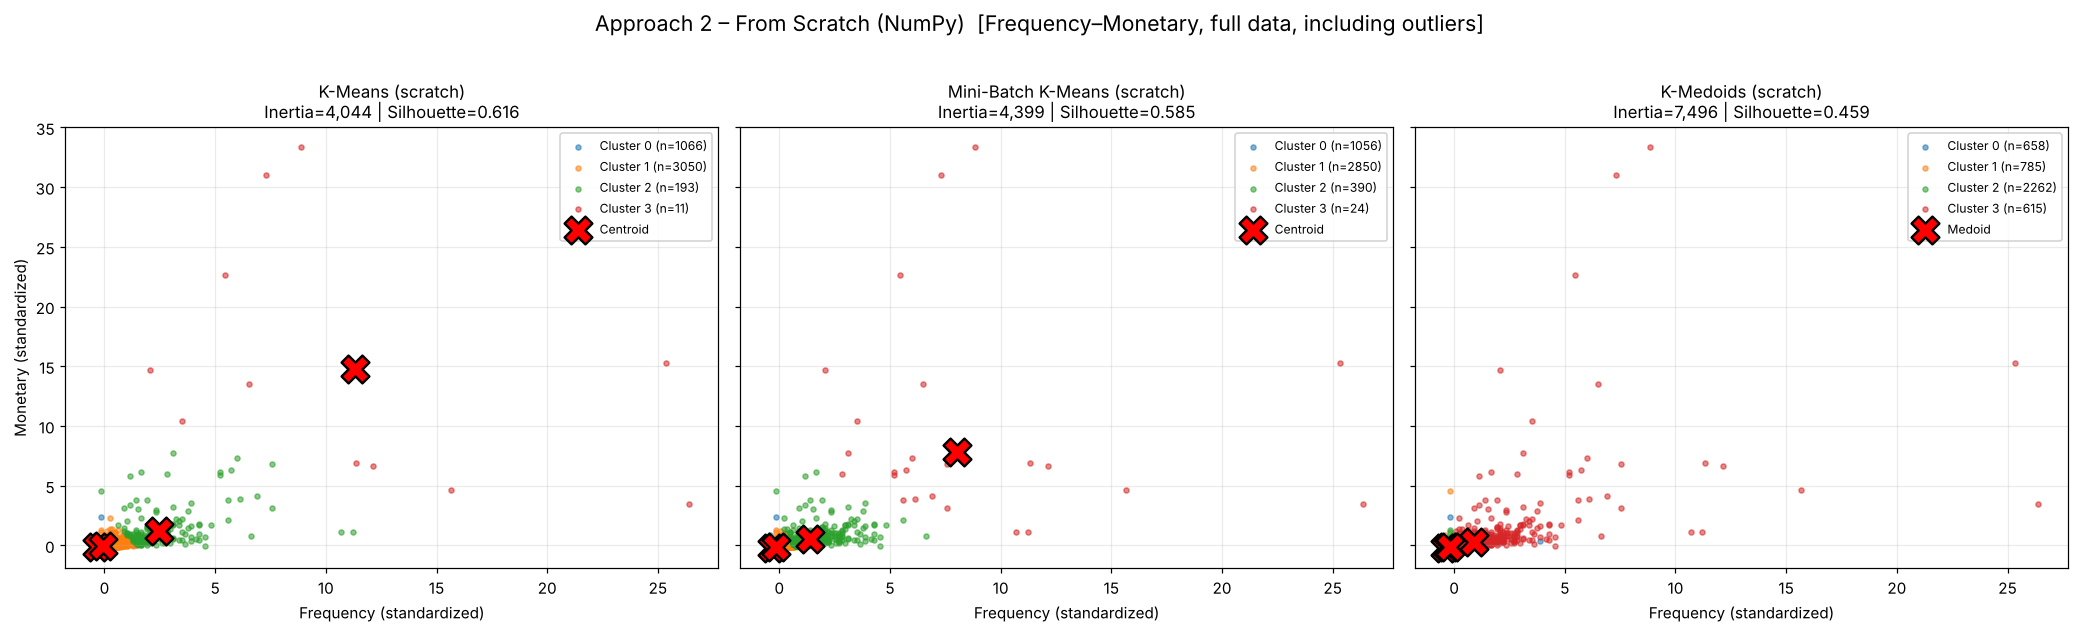

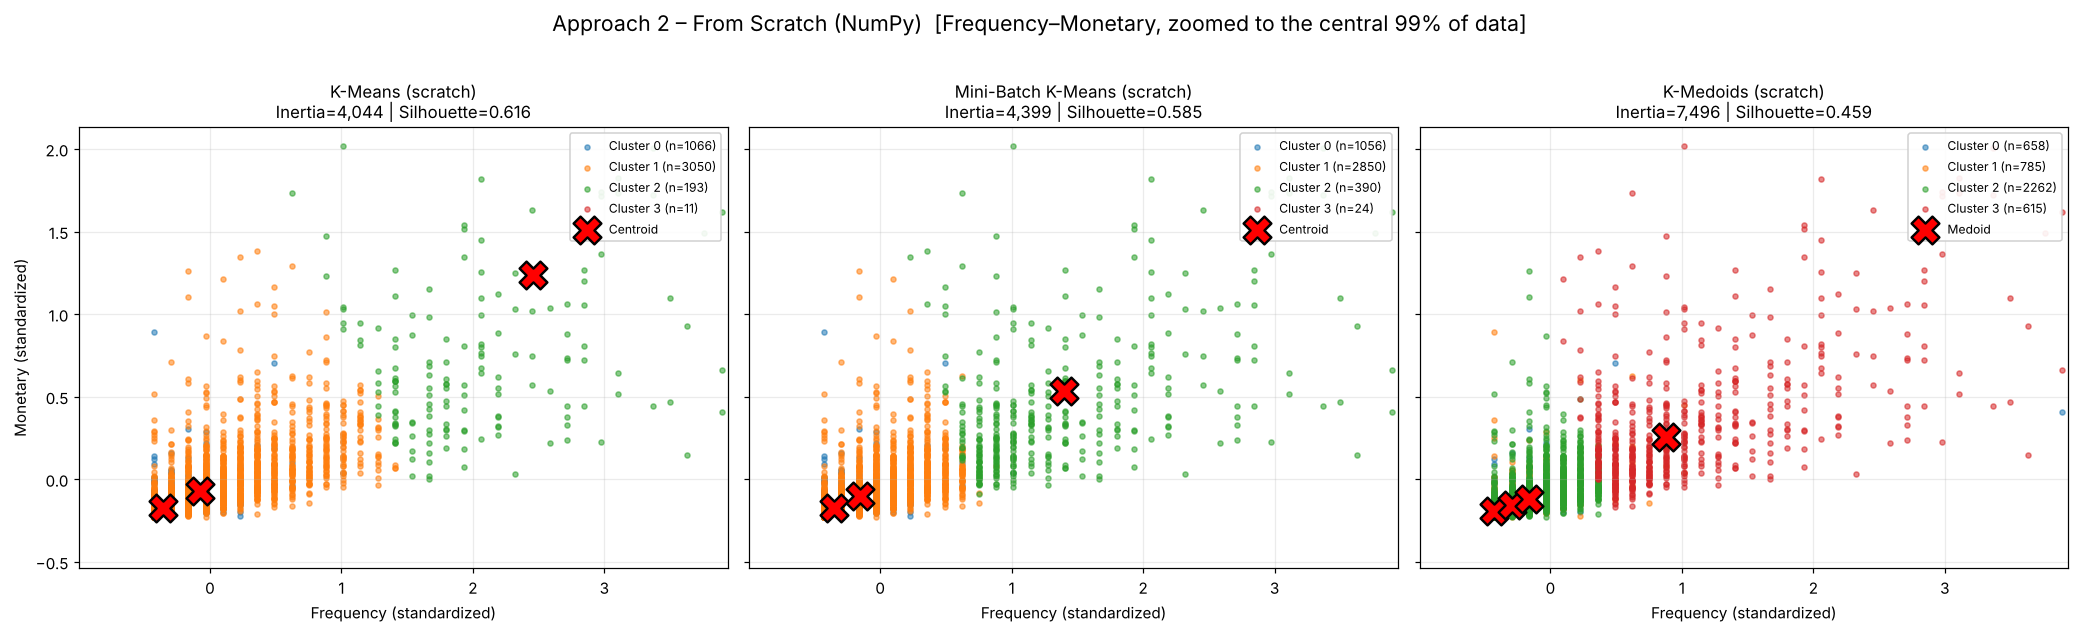

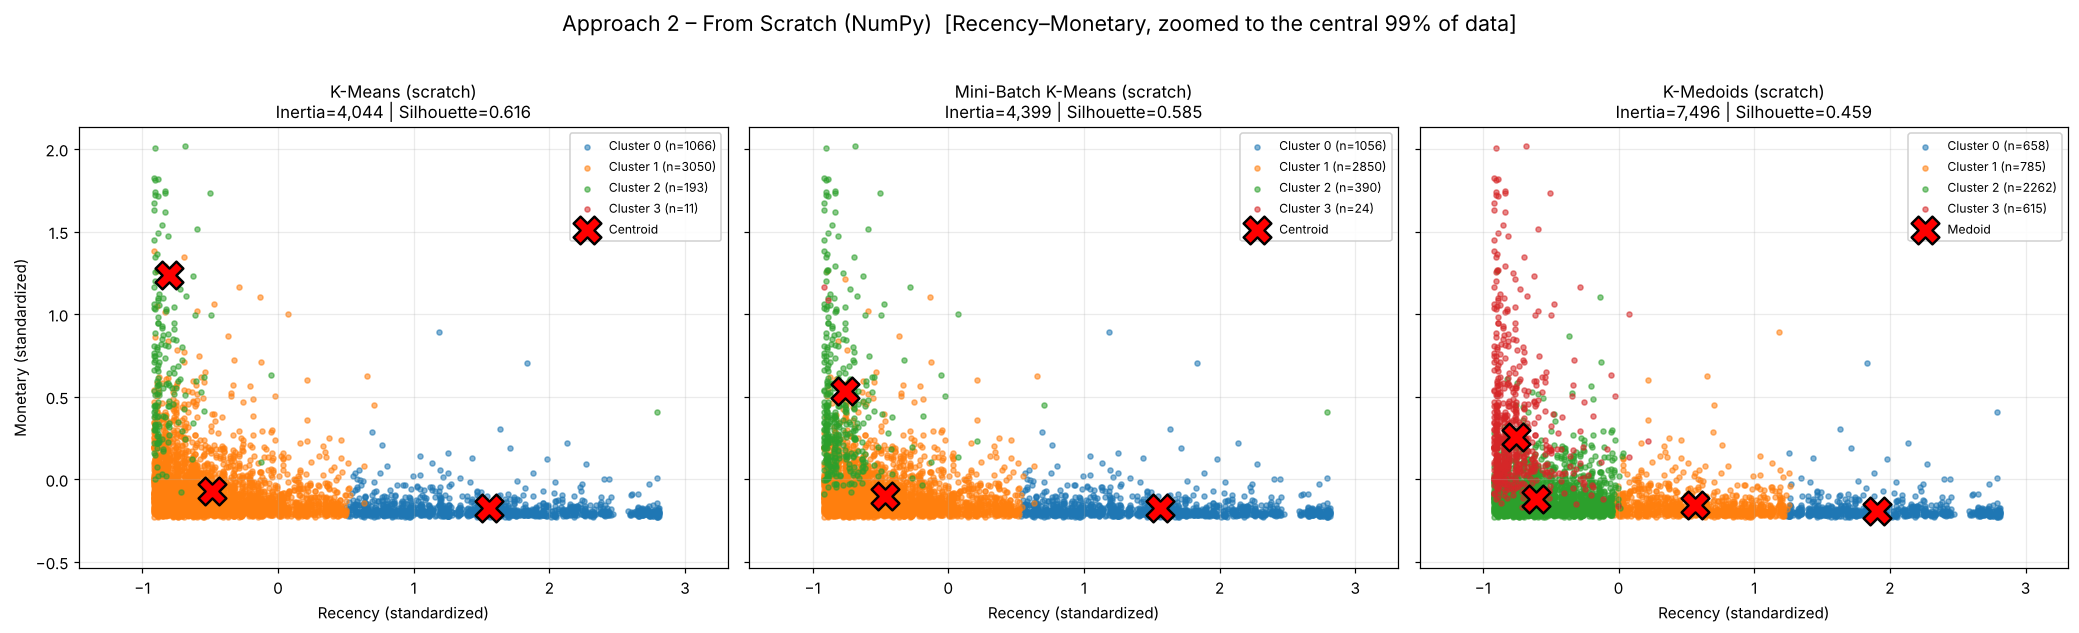

In [21]:
title_cu = "Approach 2 – From Scratch (NumPy)"
plot_clusters_1x3(X, cu_results, title_cu, axes_idx=(1, 2), zoom=False)
plot_clusters_1x3(X, cu_results, title_cu, axes_idx=(1, 2), zoom=True)
plot_clusters_1x3(X, cu_results, title_cu, axes_idx=(0, 2), zoom=True)

## 4.4. Đối chiếu trực tiếp Scikit-learn ↔ From Scratch
* **Cost tương đối:** so sánh hàm mục tiêu mà từng thuật toán tối ưu (WCSS cho hai họ K-Means, Abs. cost cho K-Medoids).
* **ARI** (Adjusted Rand Index): mức độ trùng khớp phân hoạch; 1.0 = giống hệt (không phụ thuộc cách đánh số cụm).
* **Sai lệch tâm:** ghép **một-một** tâm sklearn với tâm scratch sao cho tổng khoảng cách nhỏ nhất (`match_centers`), rồi lấy trung bình và giá trị lớn nhất (không gian đã chuẩn hóa).
* **Thời gian / lần chạy đầy đủ:** các cấu hình có số lần tối ưu khác nhau (sklearn `KMedoids` chạy 1 lần, bản scratch `n_init=3`; `MiniBatchKMeans` mặc định chỉ tối ưu 1 lần), nên chia thời gian cho số lần chạy đầy đủ để so sánh công bằng.

Hai dòng phụ để tách lỗi **cài đặt** khỏi khác biệt **cấu hình**:
* *K-Means (scratch dùng k-means++)*: bản chính của Phần 4 khởi tạo ngẫu nhiên, còn sklearn dùng k-means++. Dòng này chạy `CustomKMeans(init="k-means++")` để so sánh cùng kiểu khởi tạo.
* *Mini-Batch (sklearn, cùng cơ chế với scratch)*: chạy `MiniBatchKMeans(n_init=1, reassignment_ratio=0)` với 10 seed và giữ nghiệm có WCSS nhỏ nhất trên toàn bộ dữ liệu, đúng cách bản scratch chọn nghiệm. `reassignment_ratio=0` tắt cơ chế của sklearn **dời các tâm nhận quá ít điểm sang điểm ngẫu nhiên**; bản scratch không có cơ chế này.

In [22]:
# sklearn Mini-Batch cấu hình tương đương bản scratch: 10 lần tối ưu đầy đủ, chọn theo WCSS toàn bộ
def mb_best_of_10():
    runs = [MiniBatchKMeans(n_clusters=N_CLUSTERS, batch_size=1024, n_init=1, reassignment_ratio=0.0,
                            random_state=SEED + s).fit(X)
            for s in range(10)]
    return min(runs, key=lambda m: compute_inertia(X, m.labels_, m.cluster_centers_))

class _Wrap:                      # để dùng lại fit_timed
    def fit_predict(self, X):
        self.model = mb_best_of_10(); return self.model.labels_

w, _, t_mb_fair = fit_timed(_Wrap, X, repeats=3)
mb_fair = {"labels": w.model.labels_, "centers": w.model.cluster_centers_, "time": t_mb_fair}

# CustomKMeans với k-means++ (cùng kiểu khởi tạo với sklearn) – kiểm tra tính đúng của cài đặt
km_pp, lab_pp, t_pp = fit_timed(lambda: CustomKMeans(n_clusters=N_CLUSTERS, init="k-means++", n_init=10,
                                                     random_state=SEED), X, repeats=3)
cu_km_pp = {"labels": lab_pp, "centers": km_pp.cluster_centers_, "time": t_pp}

# (nhãn, kết quả sklearn, số lần tối ưu sklearn, kết quả scratch, số lần tối ưu scratch)
pairs = [
    ("K-Means",                                sk_results["K-Means"],            10, cu_results["K-Means (scratch)"],            10),
    ("K-Means (scratch dùng k-means++)",       sk_results["K-Means"],            10, cu_km_pp,                                   10),
    ("Mini-Batch K-Means (sklearn mặc định)",  sk_results["Mini-Batch K-Means"],  1, cu_results["Mini-Batch K-Means (scratch)"], 10),
    ("Mini-Batch K-Means (sklearn, cùng cơ chế với scratch)", mb_fair,           10, cu_results["Mini-Batch K-Means (scratch)"], 10),
    ("K-Medoids (PAM)",                        sk_results["K-Medoids (PAM)"],     1, cu_results["K-Medoids (scratch)"],           3),
]

rows = []
for label, sk, n_sk, cu, n_cu in pairs:
    is_medoid = "Medoids" in label
    metric_fn = compute_abs_cost if is_medoid else compute_inertia
    sk_obj = metric_fn(X, sk["labels"], sk["centers"])
    cu_obj = metric_fn(X, cu["labels"], cu["centers"])
    gap = match_centers(sk["centers"], cu["centers"])
    rows.append({
        "Thuật toán": label,
        "Hàm mục tiêu": "Abs. cost" if is_medoid else "WCSS",
        "sklearn": sk_obj,
        "scratch": cu_obj,
        "Chênh lệch (%)": 100.0 * (cu_obj - sk_obj) / sk_obj,
        "ARI": adjusted_rand_index(sk["labels"], cu["labels"]),
        "Sai lệch tâm TB": gap.mean(),
        "Sai lệch tâm Max": gap.max(),
        "Time sklearn (s)": sk["time"],
        "Time scratch (s)": cu["time"],
        "Lần tối ưu (sk/scratch)": f"{n_sk}/{n_cu}",
        "Time/lần sklearn": sk["time"] / n_sk,
        "Time/lần scratch": cu["time"] / n_cu,
    })

comparison = pd.DataFrame(rows).set_index("Thuật toán")
display(comparison.round(4))

sk_med = set(sk_results["K-Medoids (PAM)"]["model"].medoid_indices_.tolist())
cu_med = set(cu_results["K-Medoids (scratch)"]["model"].medoid_indices_.tolist())
print("Medoid của sklearn_extra (CustomerID):", sorted(rfm.index[list(sk_med)].tolist()))
print("Medoid của scratch       (CustomerID):", sorted(rfm.index[list(cu_med)].tolist()))
print("Số medoid trùng nhau:", len(sk_med & cu_med), "/", N_CLUSTERS)

,Hàm mục tiêu,sklearn,scratch,Chênh lệch (%),ARI,Sai lệch tâm TB,Sai lệch tâm Max,Time sklearn (s),Time scratch (s),Lần tối ưu (sk/scratch),Time/lần sklearn,Time/lần scratch
Thuật toán,,,,,,,,,,,,
K-Means,WCSS,4027.5891,4044.4940,0.4197,0.9286,2.2411,7.2683,0.0280,0.0920,10/10,0.0028,0.0092
K-Means (scratch dùng k-means++),WCSS,4027.5891,4026.8486,-0.0184,0.9941,0.0422,0.1624,0.0280,0.0478,10/10,0.0028,0.0048
Mini-Batch K-Means (sklearn mặc định),WCSS,6349.6774,4399.0876,-30.7195,0.4221,2.4722,7.9657,0.0167,0.0440,1/10,0.0167,0.0044
"Mini-Batch K-Means (sklearn, cùng cơ chế với scratch)",WCSS,4060.0710,4399.0876,8.3500,0.7766,4.1471,13.3863,0.0768,0.0440,10/10,0.0077,0.0044
K-Medoids (PAM),Abs. cost,2122.4663,2122.4663,0.0000,1.0000,0.0000,0.0000,13.2872,5.8072,1/3,13.2872,1.9357


Medoid của sklearn_extra (CustomerID): [12834, 15402, 16670, 17886]
Medoid của scratch       (CustomerID): [12834, 15402, 16670, 17886]
Số medoid trùng nhau: 4 / 4


## 4.5. Chân dung cụm & gợi ý hành động marketing
So sánh chân dung cụm của **K-Medoids (scratch) trên `X`** với **K-Means trên `X_log`** (bản đối chứng ở 2.5). Chân dung dùng **trung vị**; cột `Monetary (mean)` được giữ lại để thấy outlier kéo trung bình đi bao xa.

In [23]:
labels_med, centers_med, _ = relabel_by_monetary(cu_results["K-Medoids (scratch)"]["labels"],
                                                 cu_results["K-Medoids (scratch)"]["centers"])
labels_log, centers_log, _ = relabel_by_monetary(log_results["K-Means"]["labels"],
                                                 log_results["K-Means"]["centers"])

for title, lab in (("K-Medoids (scratch) trên X", labels_med), ("K-Means trên X_log", labels_log)):
    prof = profile_clusters(rfm, lab)
    prof["Tỷ trọng KH (%)"] = (100 * prof["Size"] / prof["Size"].sum()).round(1)
    prof["Tỷ trọng doanh thu (%)"] = (100 * rfm.groupby(lab)["Monetary"].sum() / rfm["Monetary"].sum()).round(1)
    print(f"=== {title} ===")
    display(prof)

top5 = rfm["Monetary"].nlargest(5).index
print("5 khách chi tiêu (ròng) lớn nhất rơi vào cụm nào?")
display(pd.DataFrame({"Monetary ròng (£)": rfm.loc[top5, "Monetary"].round(0),
                      "Cụm – K-Medoids/X": labels_med[rfm.index.get_indexer(top5)],
                      "Cụm – K-Means/X_log": labels_log[rfm.index.get_indexer(top5)]}))

=== K-Medoids (scratch) trên X ===


,Size,Recency (median),Frequency (median),Monetary (median),Monetary (mean),Tỷ trọng KH (%),Tỷ trọng doanh thu (%)
Cluster,,,,,,,
0,658,283.0,1.0,266.2,433.8,15.2,3.4
1,785,149.0,2.0,459.9,750.1,18.2,7.1
2,2262,31.0,2.0,692.0,997.7,52.4,27.2
3,615,10.0,11.0,3965.2,8390.1,14.2,62.2


=== K-Means trên X_log ===


,Size,Recency (median),Frequency (median),Monetary (median),Monetary (mean),Tỷ trọng KH (%),Tỷ trọng doanh thu (%)
Cluster,,,,,,,
0,940,255.0,1.0,283.5,377.7,21.8,4.3
1,1388,51.0,1.0,338.8,383.5,32.1,6.4
2,1447,30.0,4.0,1310.1,1583.0,33.5,27.6
3,545,10.0,12.0,4582.6,9381.4,12.6,61.7


5 khách chi tiêu (ròng) lớn nhất rơi vào cụm nào?


,Monetary ròng (£),Cụm – K-Medoids/X,Cụm – K-Means/X_log
CustomerID,,,
14646,278778.0,3,3
18102,259657.0,3,3
17450,189736.0,3,3
14911,128882.0,3,3
12415,123638.0,3,3


### Gợi ý phân khúc (theo K-Medoids scratch trên `X`)

| Cụm | Tên gợi ý | KH / Doanh thu | Chân dung (trung vị) | Hành động gợi ý |
|---|---|---|---|---|
| 0 | **Đã rời bỏ** | 15,2% / 3,4% | 283 ngày chưa mua, 1 đơn, £266 | Win-back chi phí thấp (một email ưu đãi); không đưa vào quảng cáo trả phí |
| 1 | **Có nguy cơ rời bỏ** | 18,2% / 7,1% | 149 ngày, 2 đơn, £460 | Kích hoạt lại: mã giảm giá có thời hạn, nhắc lại sản phẩm từng mua |
| 2 | **Khách phổ thông đang hoạt động** | 52,4% / 27,2% | 31 ngày, 2 đơn, £692 | Bán chéo, khuyến khích đơn thứ 3–4, chương trình tích điểm |
| 3 | **Giá trị cao / trung thành** | 14,2% / 62,2% | 10 ngày, 11 đơn, £3.965 | Chăm sóc VIP, ưu tiên hàng mới; **tách riêng nhóm khách sỉ** (cả 5 khách lớn nhất đều ở đây) để quản lý theo tài khoản B2B |

**So với K-Means trên `X_log`:** nhóm giá trị cao gần như giống nhau (≈ 13–14% khách, ≈ 62% doanh thu, chứa cả top-5). Khác biệt nằm ở nhóm giữa: K-Means/`X_log` tách **khách mới mua 1 lần** (cụm 1: 51 ngày, 1 đơn, £339, chiếm 32% khách) khỏi **khách mua lặp lại** (cụm 2: 30 ngày, 4 đơn, £1.310). Nếu mục tiêu là tăng tỷ lệ mua lại thì cách chia này hữu ích hơn.

## 4.6. Kết luận
| Tiêu chí | K-Means | Mini-Batch K-Means | K-Medoids (PAM) |
|---|---|---|---|
| Tâm cụm | Trung bình (điểm ảo) | Trung bình di động | Điểm dữ liệu **thật** |
| Hàm mục tiêu | $\sum\lVert x-\mu\rVert^2$ | Xấp xỉ WCSS qua mini-batch | $\sum d(x,m)$ |
| Độ phức tạp / vòng | $O(NKd)$ | $O(BKd)$, $B\ll N$ | $O(K(N-K)N)$ + ma trận $O(N^2)$ bộ nhớ |
| Nhạy outlier (đo ở 2.5) | **Cao** trên `X` (ARI lõi 0,53; 2 cụm dành cho outlier); vẫn đáng kể trên `X_log` (0,70) | Không kết luận được: tự dao động mạnh giữa các seed | **Thấp** (ARI lõi 0,95 trên `X`, 0,94 trên `X_log`) |
| Khả năng diễn giải | Tâm có thể không tồn tại | Tương tự K-Means | Tra được khách hàng đại diện |

**Điểm rút ra từ thí nghiệm:**
1. **Tiền xử lý quyết định phần lớn câu chuyện.** Trừ đơn hủy loại bỏ hai “cá voi” giả (12346 và 16446, hủy 100% giá trị). Bỏ qua bước này sẽ dẫn tới phân tích sai về chính những outlier mà bài toán đang nghiên cứu. StandardScaler nén phần lõi rất mạnh (IQR của M chỉ 0,16, so với 1,34 khi dùng `log1p`).
2. **Mức tương đương giữa From Scratch và Scikit-learn (bảng 4.4):**
   * **K-Medoids:** trùng hoàn toàn: 4/4 medoid, ARI = 1, cost chênh 0%.
   * **K-Means:** với khởi tạo ngẫu nhiên, bản scratch dừng ở một cực tiểu địa phương khác (WCSS cao hơn 0,4%, ARI 0,93). Khác biệt nằm ở cách tách nhóm cá voi (11 so với 6 khách). Dùng k-means++ như sklearn thì WCSS chênh −0,02% và ARI 0,99, tức cài đặt đúng. Các cụm outlier rất nhỏ là những cực tiểu kém ổn định.
   * **Mini-Batch:** sklearn mặc định có WCSS cao hơn ~31% chủ yếu do cơ chế dời tâm ít điểm (`reassignment_ratio`). Tắt cơ chế này và chọn nghiệm như bản scratch thì sklearn đạt WCSS tốt hơn bản scratch khoảng 8%, ARI 0,78. Phần chênh còn lại đến từ chuỗi batch ngẫu nhiên và cách khởi tạo (sklearn: k-means++ trên tập con; scratch: ngẫu nhiên).
3. **Chống nhiễu:** đo bằng thí nghiệm bỏ outlier (không dùng chỉ số tâm–trung vị vốn thiên vị medoid), K-Medoids ổn định nhất ở cả hai không gian. K-Means trên `X` dành hẳn hai cụm cho outlier và đổi cách chia lõi khi bỏ outlier.
4. **Tốc độ:** với N ≈ 4.300, Mini-Batch gần như không nhanh hơn K-Means (cả hai chỉ mất vài phần trăm giây); lợi thế chỉ rõ khi N lớn hơn nhiều. K-Medoids đắt nhất (ma trận $N\times N$, vài giây mỗi lần chạy). Với dữ liệu hàng trăm nghìn điểm cần CLARA/CLARANS hoặc lấy mẫu. Thời gian đo phụ thuộc máy, chỉ mang tính tham khảo.
5. **Khuyến nghị:**
   * Cần giữ outlier trong không gian tuyến tính và cần đại diện diễn giải được → **K-Medoids** (trên mẫu con nếu dữ liệu lớn).
   * Dùng (Mini-Batch) K-Means → nên `log1p` cho F, M, hoặc tách riêng nhóm khách sỉ trước khi phân cụm.
   * Chọn K theo tiêu chí nghiệp vụ; Silhouette trên dữ liệu có outlier dễ gây hiểu sai (K = 2 đạt 0,90 chỉ vì tách 22 khách).